# 16 · Clustering, Vector Search & Experiments
*AI Foundations · Notebook 16 of 19*

Many AI systems have to organize a huge pile of *unlabeled* things: customers, documents, images,
embedding vectors. This notebook builds three tools for that job and shows how they fit together.
**Clustering** (K-means) groups similar items around centroids. **Vector search** finds the nearest
neighbors of a query among tens of thousands of vectors in a fraction of a millisecond by searching
only the most promising clusters, and **randomized experiments** tell you whether a decision built
on those groups actually created value. All three share one geometric core, the squared Euclidean
distance to a centroid, and one engineering habit: *write the decision criteria down before you
look at the results, then choose the simplest option that meets them.*

**What you will learn**
- K-means from scratch: Lloyd's algorithm, inertia, why inertia can never go up, k-means++,
  `n_init`, empty clusters, and an exact match with scikit-learn.
- Why one feature can silently dominate squared distances, and how `log1p`, winsorizing,
  `StandardScaler` and `RobustScaler` fix it. Why new points must go through the *same fitted*
  pipeline, and what goes wrong when they do not.
- Business-rule routing *before* clustering: the Herfindahl–Hirschman concentration index (HHI),
  its range $[1/n, 1]$, and the trap of single-order customers.
- A full RFM segmentation case study on a synthetic two-and-a-half-year transaction log: two
  snapshots, three preprocessing pipelines × three values of $K$, and an explicit screening table
  (stability via the adjusted Rand index, bootstrap quantiles, minimum cluster size, feature
  dominance, silhouette in a common space, temporal stability).
- Proving business value: randomized assignment with a control group, uplift, incremental profit
  after costs, how non-random designs mislead (confounding), bootstrap confidence intervals and
  sample-size intuition.
- Approximate nearest-neighbor (ANN) search: exact search cost, an IVF index from scratch, then
  FAISS (an open-source library from Meta AI) with Flat, IVF-Flat and HNSW indexes, Recall@k,
  recall–latency curves and a defensible rule for picking the operating point.

**Prerequisites:** NumPy and pandas, vectors and dot products, mean/variance/quantiles
(Notebook 15), and a little probability.      **Estimated time:** ~5 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. K-means from scratch
2. Distances and preprocessing: who controls the distance?
3. Business rules before clustering: concentration (HHI) routing
4. Case study: RFM segmentation you can defend
5. Proving value: randomized experiments, uplift and incremental profit
6. Vector search: from exact k-NN to IVF and HNSW
7. Quiz
8. Summary and going further

## 0. Setup

The cell below imports everything, fixes the random seed, sets one plotting style for the whole
notebook and defines two helpers: `ensure()` (installs a missing package on demand, something we
need for FAISS later) and `run_check()` (the tiny test harness used by every exercise).

We also cap the number of CPU threads that the linear-algebra libraries may use. Our datasets are
small, so extra threads mostly add overhead, and single-thread timings are easier to compare later
when we measure search latency.

In [1]:
import importlib
import itertools
import random
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score, silhouette_score
from threadpoolctl import threadpool_limits

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)
threadpool_limits(1)          # keep BLAS/OpenMP to one thread: small data, reproducible timings

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
DATA_DIR = Path("data")       # not needed here: every dataset in this notebook is generated in code


def ensure(pkg: str, import_name: str | None = None):
    """Import a package, installing it with pip first if it is missing."""
    name = import_name or pkg
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(name)


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | scikit-learn 1.9.1 | matplotlib 3.11.2


---
## 1. K-means from scratch

### 1.1 The problem

> **Intuition.** A city wants to open $K$ bike-repair kiosks. Every cyclist will walk to the kiosk
> nearest to home, and the city wants the total *squared* walking distance to be as small as
> possible. If you already know which cyclists use which kiosk, the best spot for each kiosk is the
> average home location of its users. If you already know where the kiosks are, each cyclist simply
> picks the closest one. K-means alternates between exactly these two easy questions.

Precisely: we have $m$ points $\mathbf{x}_1,\dots,\mathbf{x}_m \in \mathbb{R}^d$, stacked as the
rows of $X \in \mathbb{R}^{m\times d}$. We want $K$ **centroids**
$\mathbf{c}_1,\dots,\mathbf{c}_K \in \mathbb{R}^d$ (rows of $C \in \mathbb{R}^{K\times d}$) and an
**assignment** $a(i) \in \{1,\dots,K\}$ of every point to one centroid, minimizing the
**inertia** (also called the within-cluster sum of squares, WCSS):

$$
J(a, C) \;=\; \sum_{i=1}^{m} \big\lVert \mathbf{x}_i - \mathbf{c}_{a(i)} \big\rVert^2
\;=\; \sum_{i=1}^{m} \sum_{j=1}^{d} \big(x_{ij} - c_{a(i)j}\big)^2 .
$$

Finding the global minimum is NP-hard in general (even for $K=2$ in high dimension), so in
practice we use a fast local method, **Lloyd's algorithm**:

1. **Assignment step.** With the centroids fixed, send each point to its nearest centroid:
   $a(i) \leftarrow \arg\min_k \lVert \mathbf{x}_i - \mathbf{c}_k \rVert^2$ (ties go to the smallest $k$).
2. **Update step.** With the assignment fixed, move each centroid to the mean of its points:
   $\mathbf{c}_k \leftarrow \frac{1}{|S_k|}\sum_{i \in S_k} \mathbf{x}_i$, where $S_k = \{i : a(i) = k\}$.
3. Repeat until the assignment stops changing.

Why the *mean* in step 2? For a fixed set $S_k$, the function
$f(\mathbf{c}) = \sum_{i\in S_k}\lVert\mathbf{x}_i-\mathbf{c}\rVert^2$ has gradient
$\nabla f(\mathbf{c}) = -2\sum_{i\in S_k}(\mathbf{x}_i-\mathbf{c})$, which is zero exactly at the
mean $\bar{\mathbf{x}}_{S_k}$. Since $f$ is a convex quadratic, that stationary point is the
minimum. An even more useful way to see it is the identity (expand the square around $\bar{\mathbf{x}}$,
the cross term vanishes because $\sum_{i}(\mathbf{x}_i-\bar{\mathbf{x}})=\mathbf{0}$):

$$
\sum_{i \in S_k} \lVert \mathbf{x}_i - \mathbf{c} \rVert^2
\;=\; \sum_{i \in S_k} \lVert \mathbf{x}_i - \bar{\mathbf{x}}_{S_k} \rVert^2
\;+\; |S_k|\,\lVert \bar{\mathbf{x}}_{S_k} - \mathbf{c} \rVert^2 .
$$

Any centroid other than the mean pays the extra, non-negative term $|S_k|\,\lVert\bar{\mathbf{x}}-\mathbf{c}\rVert^2$.

### 1.2 A worked example by hand

Six points in the plane, $K = 2$, and a deliberately poor start: both initial centroids are
taken from the lower-left group, $\mathbf{c}_1 = A = (1,1)$ and $\mathbf{c}_2 = C = (1,3)$.

| point | A | B | C | D | E | F |
|---|---|---|---|---|---|---|
| coordinates | (1, 1) | (2, 1) | (1, 3) | (6, 5) | (7, 4) | (8, 6) |

**Iteration 1, assignment.** Squared distances to $\mathbf{c}_1=(1,1)$ / $\mathbf{c}_2=(1,3)$:
A: 0 / 4, B: 1 / 5, C: 4 / 0, D: 41 / 29, E: 45 / 37, F: 74 / 58. So $S_1=\{A,B\}$,
$S_2=\{C,D,E,F\}$ and $J = 0+1+0+29+37+58 = 125$.

**Iteration 1, update.** $\mathbf{c}_1 = \text{mean}(A,B) = (1.5, 1)$ and
$\mathbf{c}_2 = \text{mean}(C,D,E,F) = (22/4, 18/4) = (5.5, 4.5)$. With the same assignment the
inertia drops to $0.25+0.25+22.5+0.5+2.5+8.5 = 34.5$.

**Iteration 2.** Point C is now closer to $\mathbf{c}_1$ ($4.25$ versus $22.5$), so it switches:
$S_1=\{A,B,C\}$, $S_2=\{D,E,F\}$, $J = 16.25$. The update gives $\mathbf{c}_1=(4/3, 5/3)$,
$\mathbf{c}_2=(7,5)$ and $J = 22/3 \approx 7.33$.

**Iteration 3.** Nobody switches, so the algorithm stops. The code below replays these steps.

In [2]:
toy = np.array([[1, 1], [2, 1], [1, 3], [6, 5], [7, 4], [8, 6]], dtype=float)
toy_names = np.array(list("ABCDEF"))
C = toy[[0, 2]].copy()                       # poor start: A and C, both in the lower-left group

rows = []
for it in range(1, 10):
    d2 = ((toy[:, None, :] - C[None, :, :]) ** 2).sum(axis=-1)    # (6, 2) squared distances
    labels = d2.argmin(axis=1)                                     # assignment step
    J_after_assign = d2[np.arange(len(toy)), labels].sum()
    C_new = np.array([toy[labels == k].mean(axis=0) for k in range(2)])   # update step
    J_after_update = ((toy - C_new[labels]) ** 2).sum()
    rows.append({"iteration": it,
                 "cluster 1": "".join(toy_names[labels == 0]), "cluster 2": "".join(toy_names[labels == 1]),
                 "J after assign": J_after_assign,
                 "c1 after update": tuple(np.round(C_new[0], 3)), "c2 after update": tuple(np.round(C_new[1], 3)),
                 "J after update": round(J_after_update, 3)})
    if np.allclose(C_new, C):
        break
    C = C_new
print(pd.DataFrame(rows).to_string(index=False))

 iteration cluster 1 cluster 2  J after assign c1 after update c2 after update  J after update
         1        AB      CDEF      125.000000      (1.5, 1.0)      (5.5, 4.5)          34.500
         2       ABC       DEF       16.250000  (1.333, 1.667)      (7.0, 5.0)           7.333
         3       ABC       DEF        7.333333  (1.333, 1.667)      (7.0, 5.0)           7.333


Every number matches the hand computation: $125 \to 34.5 \to 16.25 \to 7.33$, and in iteration 3
the assignment (and therefore the centroids) no longer changes.

### 1.3 Why the inertia can never go up

Look at what each step does to $J(a, C)$:

* **Assignment step** ($C$ fixed). Each point's term $\lVert\mathbf{x}_i-\mathbf{c}_{a(i)}\rVert^2$
  is replaced by the *smallest* of its $K$ possible values, so no term can increase.
* **Update step** ($a$ fixed). By the identity in §1.1, the mean is the best possible centroid for
  each cluster, so no cluster's sum can increase.

So the sequence of inertias is non-increasing and bounded below by $0$. Moreover, $J$ after an
update step depends only on the partition $\{S_1,\dots,S_K\}$, and there are at most $K^m$
partitions. If we break ties in favor of a point's *current* cluster, the assignment changes only
when some point finds a *strictly* closer centroid, so $J$ strictly decreases and that partition
can never be visited again. A finite set of partitions, none visited twice, means Lloyd's
algorithm **must stop after finitely many iterations**. (Code usually breaks ties by the smallest
index, as `argmin` does. With real-valued data exact ties are so rare that this makes no
practical difference.)

> **Common pitfall.** "Converged" means "reached a fixed point", *not* "found the best clustering".
> Lloyd's algorithm stops at a **local** minimum that depends on the starting centroids. The
> remedy is good initialization (k-means++) plus several restarts (`n_init`), keeping the run with
> the lowest inertia.

### 1.4 A vectorized implementation

For $m$ points and $K$ centroids we need all $mK$ squared distances. Broadcasting
`X[:, None, :] - C[None, :, :]` builds an $m\times K\times d$ array, which is wasteful. Expanding the
square gives a version that needs only one matrix product:

$$
\lVert \mathbf{x}_i - \mathbf{c}_k \rVert^2 = \lVert\mathbf{x}_i\rVert^2 - 2\,\mathbf{x}_i^\top\mathbf{c}_k + \lVert\mathbf{c}_k\rVert^2 ,
\qquad
D = \underbrace{\mathbf{n}_X \mathbf{1}_K^\top}_{m\times K} - 2\,X C^\top + \mathbf{1}_m \mathbf{n}_C^\top ,
$$

where $\mathbf{n}_X \in \mathbb{R}^m$ and $\mathbf{n}_C \in \mathbb{R}^K$ hold the squared row norms.

> **Common pitfall (numerics).** The expanded form subtracts large, nearly equal numbers when the
> points are far from the origin, so it can return tiny *negative* values. Clip at zero, and if the
> data sit far from the origin, center them first. Libraries (including FAISS later) use the same
> trick and the same safeguards.

**Empty clusters.** If no point picks centroid $k$, its mean is undefined ($0/0$). A standard fix
(scikit-learn uses a variant of it) is to move the empty centroid onto the point that is currently
*worst served*, the one with the largest squared distance to its centroid. That point's own term
drops to zero and nobody else gets worse, so the "inertia never increases" argument survives.

In [3]:
def sq_dists(X: np.ndarray, C: np.ndarray) -> np.ndarray:
    """Squared Euclidean distances between the rows of X (m, d) and of C (K, d) -> (m, K)."""
    nx = np.einsum("ij,ij->i", X, X)[:, None]
    nc = np.einsum("ij,ij->i", C, C)[None, :]
    return np.maximum(nx - 2.0 * X @ C.T + nc, 0.0)          # clip tiny negatives from round-off


def kmeans_lloyd(X: np.ndarray, C0: np.ndarray, max_iter: int = 300) -> dict:
    """Lloyd's algorithm from initial centroids C0 (K, d). Stops when the assignment is stable."""
    C = np.array(C0, dtype=float, copy=True)
    K, m = len(C), len(X)
    labels = np.full(m, -1)
    history, n_reseeded = [], 0
    for it in range(1, max_iter + 1):
        D = sq_dists(X, C)
        new_labels = D.argmin(axis=1)
        d2 = D[np.arange(m), new_labels]
        history.append(d2.sum())                               # inertia after this assignment
        if np.array_equal(new_labels, labels):
            break                                              # fixed point reached
        labels = new_labels
        counts = np.bincount(labels, minlength=K)
        sums = np.zeros_like(C)
        np.add.at(sums, labels, X)                             # per-cluster coordinate sums
        for k in range(K):
            if counts[k] > 0:
                C[k] = sums[k] / counts[k]
            else:                                              # empty cluster: re-seed it
                worst = d2.argmax()
                C[k] = X[worst]
                d2[worst] = 0.0
                n_reseeded += 1
    return {"centers": C, "labels": labels, "inertia": history[-1], "history": history,
            "n_iter": it, "n_reseeded": n_reseeded}


res_toy = kmeans_lloyd(toy, toy[[0, 2]])
print("labels :", res_toy["labels"], "| centers:", np.round(res_toy["centers"], 3).tolist())
print("inertia after each assignment:", np.round(res_toy["history"], 3).tolist())

labels : [0 0 0 1 1 1] | centers: [[1.333, 1.667], [7.0, 5.0]]
inertia after each assignment: [125.0, 16.25, 7.333]


The function records the inertia right after each assignment step (not after each update, so the
34.5 from the table above does not appear), and the history reads $125 \to 16.25 \to 7.33$. The
third assignment step reproduced the previous labels, which is the check that nothing changed, so
the loop stopped there.

Now a less trivial dataset: 1,200 points from six Gaussian "blobs" of different widths arranged on
a $2\times 3$ grid. Neighboring blobs are close enough that a bad start can merge two of them and
split another. We will reuse this dataset several times in this section.

In [4]:
blob_centers = np.array([[0, 0], [0, 6], [6, 0], [6, 6], [12, 0], [12, 6]], dtype=float)
X_blob, y_blob = make_blobs(n_samples=1200, centers=blob_centers,
                            cluster_std=[1.0, 1.4, 0.8, 1.2, 1.5, 0.9], random_state=SEED)
print("X_blob shape:", X_blob.shape, "| points per true blob:", np.bincount(y_blob).tolist())

# A random start: K points drawn uniformly from the data
init_rng = np.random.default_rng(3)
C0_random = X_blob[init_rng.choice(len(X_blob), size=6, replace=False)]
res_blob = kmeans_lloyd(X_blob, C0_random)
print(f"random start -> {res_blob['n_iter']} iterations, final inertia {res_blob['inertia']:.1f}")
print("inertia history (first 8):", np.round(res_blob["history"][:8], 1).tolist())
assert np.all(np.diff(res_blob["history"]) <= 1e-9), "inertia increased: bug!"

X_blob shape: (1200, 2) | points per true blob: [200, 200, 200, 200, 200, 200]
random start -> 16 iterations, final inertia 6210.5
inertia history (first 8): [14699.3, 7979.4, 6406.9, 6250.1, 6227.6, 6219.5, 6216.9, 6216.1]


The `assert` encodes the monotonicity theorem from §1.3 as a unit test: if a future edit ever
made the inertia rise, the cell would fail loudly.

**Does it match scikit-learn?** If we start `sklearn.cluster.KMeans` from *the same* initial
centroids, with one initialization and the plain Lloyd algorithm, it must land on exactly the same
fixed point. (Because we pass the initial centroids explicitly, scikit-learn keeps their order, so
even the cluster numbers match. In general cluster numbers are arbitrary, which is why we also
compare the partitions with the adjusted Rand index, introduced properly in §4.)

In [5]:
sk = KMeans(n_clusters=6, init=C0_random, n_init=1, algorithm="lloyd", max_iter=300, tol=0.0).fit(X_blob)
print(f"max |centroid difference| = {np.abs(sk.cluster_centers_ - res_blob['centers']).max():.2e}")
print(f"inertia: ours {res_blob['inertia']:.4f} | sklearn {sk.inertia_:.4f}")
print(f"same partition (ARI): {adjusted_rand_score(sk.labels_, res_blob['labels']):.4f}")

max |centroid difference| = 7.11e-15
inertia: ours 6210.5357 | sklearn 6210.5357
same partition (ARI): 1.0000


### 1.5 Initialization: random starts, k-means++ and `n_init`

**k-means++** (Arthur & Vassilvitskii, 2007) spreads the initial centroids out:

1. Pick the first centroid uniformly at random among the data points.
2. For every point compute $D(\mathbf{x}_i)^2$, the squared distance to the *nearest centroid
   chosen so far*.
3. Pick the next centroid at random with probability
   $p_i = D(\mathbf{x}_i)^2 / \sum_{j} D(\mathbf{x}_j)^2$ ("$D^2$ sampling"). Repeat until $K$ are chosen.

Points far from all current centroids are likely picks, and points already covered are almost
never picked. **By hand** on the toy data with first centroid $A=(1,1)$: the squared distances are
A 0, B 1, C 4, D 41, E 45, F 74 (total 165), so the second centroid is D, E or F with probability
$(41+45+74)/165 = 160/165 \approx 0.97$, which is almost guaranteed to cover the second group. The
expected inertia of k-means++ seeding alone is within a factor $8(\ln K + 2)$ of the optimum, a
guarantee no uniform random start has.

Even with k-means++, a single run can end in a poor local minimum. If one run reaches the best
solution with probability $p$, then the best of $n$ independent runs misses it with probability
$(1-p)^n$. That is what scikit-learn's `n_init` parameter buys you.

In [6]:
def kmeanspp_init(X: np.ndarray, K: int, rng: np.random.Generator) -> np.ndarray:
    """k-means++ seeding: first centroid uniform, then D^2 sampling."""
    centers = [X[rng.integers(len(X))]]
    d2 = ((X - centers[0]) ** 2).sum(axis=1)
    for _ in range(1, K):
        idx = rng.choice(len(X), p=d2 / d2.sum())
        centers.append(X[idx])
        d2 = np.minimum(d2, ((X - X[idx]) ** 2).sum(axis=1))   # distance to the nearest chosen center
    return np.array(centers)


def random_init(X, K, rng):
    return X[rng.choice(len(X), size=K, replace=False)]


n_runs = 200
final = {"random": [], "k-means++": []}
init_rng = np.random.default_rng(SEED)
for _ in range(n_runs):
    final["random"].append(kmeans_lloyd(X_blob, random_init(X_blob, 6, init_rng))["inertia"])
    final["k-means++"].append(kmeans_lloyd(X_blob, kmeanspp_init(X_blob, 6, init_rng))["inertia"])
final = {k: np.array(v) for k, v in final.items()}
best_J = min(v.min() for v in final.values())
summary_init = pd.DataFrame({
    name: {"median inertia": np.median(v), "worst inertia": v.max(),
           "P(within 0.1% of best)": np.mean(v <= best_J * 1.001)}
    for name, v in final.items()}).T
summary_init["P(best of 10 runs is within 0.1%)"] = 1 - (1 - summary_init["P(within 0.1% of best)"]) ** 10
print(f"best inertia seen in {2 * n_runs} runs: {best_J:.1f}")
print(summary_init.round(3))

best inertia seen in 400 runs: 2979.6
           median inertia  worst inertia  P(within 0.1% of best)  P(best of 10 runs is within 0.1%)
random           2979.648       6632.240                   0.625                                1.0
k-means++        2979.648       6564.077                   0.780                                1.0


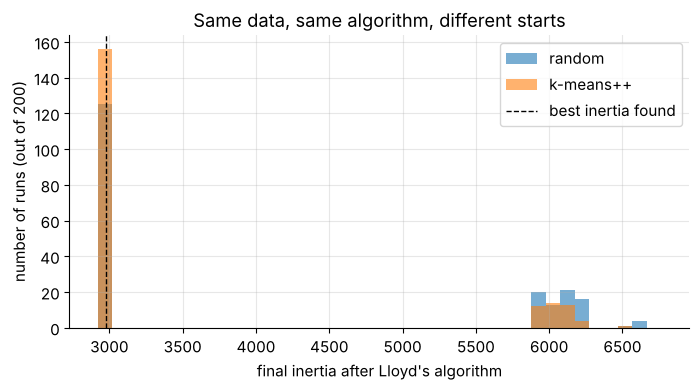

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(best_J * 0.98, max(v.max() for v in final.values()) * 1.02, 40)
for name, v in final.items():
    ax.hist(v, bins=bins, alpha=0.6, label=name)
ax.axvline(best_J, color="k", ls="--", lw=1, label="best inertia found")
ax.set_xlabel("final inertia after Lloyd's algorithm")
ax.set_ylabel("number of runs (out of 200)")
ax.set_title("Same data, same algorithm, different starts")
ax.legend()
plt.show()

Read the table, not just the picture. A single random start ends within 0.1% of the best inertia
in 62.5% of runs, a single k-means++ start in 78%: better, but even k-means++ falls into a clearly
worse local minimum in about one run out of five. Restarts fix this: if one run succeeds with
probability $p = 0.625$, ten independent runs all fail with probability $0.375^{10} \approx 6\times10^{-5}$
(the last column, rounded to 1.0). On real high-dimensional data every restart costs time, so good
seeding *and* a few restarts is the standard recipe (`KMeans(init="k-means++", n_init=...)`).

Let us also see what a local minimum looks like and watch the empty-cluster rule fire.

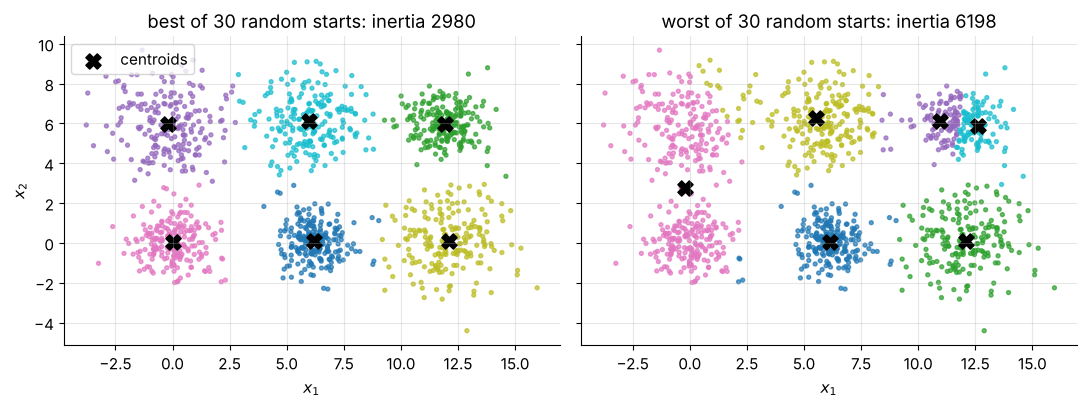

centroid at (100, 100): re-seeded 1 time(s); final inertia 2979.6; smallest cluster has 190 points


In [8]:
worst_seed_rng = np.random.default_rng(SEED)
runs = [kmeans_lloyd(X_blob, random_init(X_blob, 6, worst_seed_rng)) for _ in range(30)]
bad = max(runs, key=lambda r: r["inertia"])
good = min(runs, key=lambda r: r["inertia"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, r, title in [(axes[0], good, "best of 30 random starts"), (axes[1], bad, "worst of 30 random starts")]:
    ax.scatter(X_blob[:, 0], X_blob[:, 1], c=r["labels"], cmap="tab10", s=8, alpha=0.7)
    ax.scatter(r["centers"][:, 0], r["centers"][:, 1], c="k", marker="X", s=120, label="centroids")
    ax.set_title(f"{title}: inertia {r['inertia']:.0f}")
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

# A start with one centroid far away from every point: it attracts nobody in the first assignment.
C0_empty = np.vstack([X_blob[:5], [[100.0, 100.0]]])
r_empty = kmeans_lloyd(X_blob, C0_empty)
print(f"centroid at (100, 100): re-seeded {r_empty['n_reseeded']} time(s); final inertia "
      f"{r_empty['inertia']:.1f}; smallest cluster has {np.bincount(r_empty['labels']).min()} points")

In the bad run, two true blobs share one centroid while another blob is split in two. Every point
is still assigned to its nearest centroid and every centroid is still the mean of its points, so
Lloyd's algorithm has no reason to move. That is exactly what a local minimum is.

### 1.6 How many clusters? Elbow and silhouette

Inertia always decreases as $K$ grows (with $K = m$ it is zero), so we cannot simply minimize it.
Two classic diagnostics:

* **Elbow:** plot the best inertia against $K$ and look for the point where adding a cluster stops
  paying off much.
* **Silhouette:** for point $i$ in cluster $S$, let $a(i)$ be its mean distance to the other points
  of $S$, and $b(i)$ its mean distance to the points of the *nearest other* cluster. Then

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}} \in [-1, 1],
$$

  close to $1$ when the point sits snugly inside its cluster, near $0$ on a boundary, negative
  when it is probably in the wrong cluster. The silhouette score is the mean of $s(i)$.
  (Silhouette uses plain, not squared, Euclidean distance by default.)

**By hand** for point A in the final toy clustering $\{A,B,C\}, \{D,E,F\}$:
$a(A) = (|AB| + |AC|)/2 = (1 + 2)/2 = 1.5$ and
$b(A) = (|AD| + |AE| + |AF|)/3 = (\sqrt{41} + \sqrt{45} + \sqrt{74})/3 \approx (6.403 + 6.708 + 8.602)/3 = 7.238$,
so $s(A) = (7.238 - 1.5)/7.238 \approx 0.793$.

s(A) by hand ≈ 0.793 | sklearn: 0.793


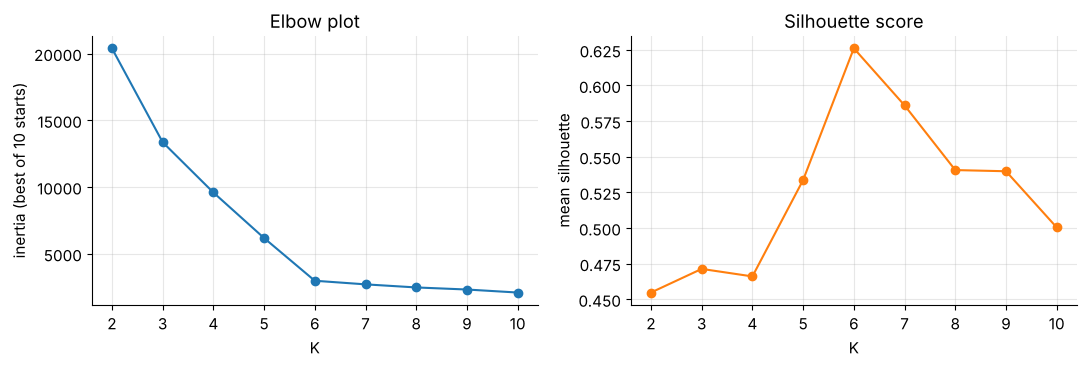

 K  inertia  silhouette
 2  20393.5       0.455
 3  13360.8       0.471
 4   9592.9       0.466
 5   6179.1       0.534
 6   2979.8       0.626
 7   2709.2       0.586
 8   2477.9       0.541
 9   2322.4       0.540
10   2096.3       0.500


In [9]:
from sklearn.metrics import silhouette_samples

print(f"s(A) by hand ≈ 0.793 | sklearn: {silhouette_samples(toy, res_toy['labels'])[0]:.3f}")

Ks = list(range(2, 11))
inertias, sils = [], []
for K in Ks:
    km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_blob)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_blob, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(Ks, inertias, "o-")
axes[0].set_xlabel("K")
axes[0].set_ylabel("inertia (best of 10 starts)")
axes[0].set_title("Elbow plot")
axes[1].plot(Ks, sils, "o-", color="C1")
axes[1].set_xlabel("K")
axes[1].set_ylabel("mean silhouette")
axes[1].set_title("Silhouette score")
plt.tight_layout()
plt.show()
print(pd.DataFrame({"K": Ks, "inertia": np.round(inertias, 1), "silhouette": np.round(sils, 3)}).to_string(index=False))

On this dataset both diagnostics agree with the truth: inertia falls steeply up to $K = 6$ (from
6179 at $K=5$ to 2980 at $K=6$) and only slowly afterwards, and the silhouette peaks at $K = 6$ (0.626).

> **Key idea.** Elbow and silhouette are *hints*, not verdicts. They answer "how well separated are
> these groups in this feature space?", not "how many customer programs should the business run?".
> In §4 we will add stability, cluster-size and usefulness criteria, and in §5 we will measure the
> value of a program built on one segment with a controlled experiment.

### ✏️ Exercise 1: nearest centroid by squared Euclidean distance

Write `nearest_centroid(X, C)` that returns the index of the nearest centroid for every row of
`X` *and* the corresponding squared distance. Break ties toward the smaller index (that is what
`argmin` does). You may use broadcasting or the expanded formula.

In [10]:
# ✏️ Exercise 1: nearest centroid
def nearest_centroid(X, C):
    """Return (labels, d2): labels[i] = argmin_k ||X[i] - C[k]||^2 and d2[i] = that minimum."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex1():
    Xt = np.array([[0.0, 0.0], [3.0, 4.0], [1.0, 1.0], [10.0, 0.0]])
    Ct = np.array([[0.0, 0.0], [2.0, 2.0], [10.0, 1.0]])
    lab, d2 = nearest_centroid(Xt, Ct)
    assert np.array_equal(np.asarray(lab), [0, 1, 0, 2]), f"labels {lab} (tie at [1, 1] must go to index 0)"
    assert np.allclose(d2, [0.0, 5.0, 2.0, 1.0]), f"squared distances {d2}"
    lab2, _ = nearest_centroid(X_blob, res_blob["centers"])
    assert np.array_equal(lab2, res_blob["labels"]), "does not reproduce the K-means labels on X_blob"


run_check("Exercise 1", _test_ex1)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def nearest_centroid(X, C):
    D = ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=-1)   # (m, K)
    labels = D.argmin(axis=1)
    return labels, D[np.arange(len(X)), labels]
```
Broadcasting builds all $m \times K$ squared distances, and `argmin` picks the first minimum, which
settles ties toward the smaller index. Point $(1,1)$ is at squared distance 2 from both $(0,0)$ and
$(2,2)$, so it goes to centroid 0.
</details>

### ✏️ Exercise 2: k-means++ sampling probabilities

Write `kmeanspp_probs(X, centers)` returning the probability that each row of `X` is chosen as
the *next* centroid by $D^2$ sampling, given the centroids already chosen (rows of `centers`).

In [11]:
# ✏️ Exercise 2: D^2 sampling probabilities
def kmeanspp_probs(X, centers):
    """p[i] = D(x_i)^2 / sum_j D(x_j)^2, with D = distance to the nearest row of `centers`."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex2():
    p = kmeanspp_probs(toy, toy[[0]])
    assert np.allclose(p, np.array([0, 1, 4, 41, 45, 74]) / 165), f"got {np.round(p, 4)}"
    p2 = kmeanspp_probs(toy, toy[[0, 4]])            # centroids at A and E
    assert np.isclose(p2.sum(), 1.0) and p2[0] == 0 and p2[4] == 0, "chosen points must get probability 0"
    assert np.allclose(p2, np.array([0, 1, 4, 2, 0, 5]) / 12), f"got {np.round(p2, 4)}"


run_check("Exercise 2", _test_ex2)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def kmeanspp_probs(X, centers):
    d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=-1).min(axis=1)
    return d2 / d2.sum()
```
With centroids A and E, the nearest-centroid squared distances are A 0, B 1, C 4, D 2, E 0, F 5
(total 12), so F is the most likely next pick.
</details>

> **Quick check.** You run K-means twice on the same data with the same $K$ and get inertias
> 812.4 and 790.1. Which result do you keep, and what does the difference tell you?

<details>
<summary>Answer</summary>

Keep the run with inertia 790.1: both are fixed points of Lloyd's algorithm, and lower inertia is
the objective. The difference tells you the problem has several local minima, so you should use
more restarts (`n_init`) or better seeding, and later check that the clusters you report are
*stable* across restarts (§4).
</details>

---
## 2. Distances and preprocessing: who controls the distance?

K-means only ever looks at one quantity, the squared Euclidean distance
$\lVert\mathbf{x}-\mathbf{c}\rVert^2 = \sum_{j=1}^{d}(x_j - c_j)^2$. It is a **sum over features**,
so we can ask how much of it each feature contributes:

$$
\text{share}_j(\mathbf{x}, \mathbf{c}) = \frac{(x_j - c_j)^2}{\sum_{l=1}^{d}(x_l - c_l)^2} .
$$

Summing the numerator over all points (each with its own centroid) gives each feature's share of
the total inertia. If one share is close to 1, the "multi-feature" clustering is really a
one-feature clustering in disguise.

### 2.1 A worked example: dollars versus orders

A customer bought **once**, recently, for a large amount: $\mathbf{x}$ = (recency 15 days,
1 order, \$640 spent in the last 12 months). Two centroids from an earlier segmentation:

| centroid | recency (days) | orders | spend (\$) |
|---|---|---|---|
| $\mathbf{c}_A$ "frequent regulars" | 18 | 14 | 600 |
| $\mathbf{c}_B$ "one-off buyers" | 40 | 1 | 95 |

**Raw units.** To $\mathbf{c}_A$: $(15-18)^2 + (1-14)^2 + (640-600)^2 = 9 + 169 + 1600 = 1778$.
To $\mathbf{c}_B$: $(15-40)^2 + 0^2 + (640-95)^2 = 625 + 0 + 297{,}025 = 297{,}650$. The customer
is labeled a *frequent regular* although they ordered once: a 13-order gap contributes only
$169/1778 \approx 9.5\%$ of the distance while a \$40 gap contributes $90\%$. In raw units one
dollar "counts" as much as one order or one day.

**Scaled units.** Divide each feature by a typical spread, say 100 days, 4 orders and \$500.
To $\mathbf{c}_A$: $0.03^2 + 3.25^2 + 0.08^2 = 0.0009 + 10.5625 + 0.0064 \approx 10.570$.
To $\mathbf{c}_B$: $0.25^2 + 0^2 + 1.09^2 = 0.0625 + 1.1881 \approx 1.251$. Now the customer is a
*one-off buyer*, which matches their behavior.

In [12]:
def distance_shares(x, c, names=None):
    """Per-feature share of the squared Euclidean distance between x and c."""
    sq = (np.asarray(x, float) - np.asarray(c, float)) ** 2
    return pd.Series(sq / sq.sum(), index=names)


x_new = np.array([15, 1, 640.0])
c_A, c_B = np.array([18, 14, 600.0]), np.array([40, 1, 95.0])
spread = np.array([100, 4, 500.0])
names3 = ["recency", "orders", "spend"]
tab = pd.DataFrame({
    "raw: share vs c_A": distance_shares(x_new, c_A, names3),
    "raw: share vs c_B": distance_shares(x_new, c_B, names3),
    "scaled: share vs c_A": distance_shares(x_new / spread, c_A / spread, names3),
    "scaled: share vs c_B": distance_shares(x_new / spread, c_B / spread, names3)})
print(tab.round(3))
print(f"raw distances    : to A {((x_new - c_A) ** 2).sum():.0f}, to B {((x_new - c_B) ** 2).sum():.0f}")
print(f"scaled distances : to A {(((x_new - c_A) / spread) ** 2).sum():.3f}, to B {(((x_new - c_B) / spread) ** 2).sum():.3f}")

         raw: share vs c_A  raw: share vs c_B  scaled: share vs c_A  scaled: share vs c_B
recency              0.005              0.002                 0.000                  0.05
orders               0.095              0.000                 0.999                  0.00
spend                0.900              0.998                 0.001                  0.95
raw distances    : to A 1778, to B 297650
scaled distances : to A 10.570, to B 1.251


### 2.2 The same effect on a whole dataset

Let us generate 3,000 customers of a small online shop. About a third are *engaged* (many orders,
recent activity) and the rest order rarely. Spend is the number of orders times an average basket
drawn from a log-normal distribution, so it has a long right tail, as real money amounts do. The
hidden `engaged` flag is kept only to check what the clustering recovers.

In [13]:
def make_customers(n: int, rng: np.random.Generator) -> pd.DataFrame:
    """Toy customer table: days since last order, orders and spend in the last 12 months."""
    engaged = rng.uniform(size=n) < 0.35
    orders = np.where(engaged, rng.poisson(9, n) + 2, rng.poisson(0.8, n) + 1)
    basket = np.exp(rng.normal(np.log(70), 0.8, n))                 # average order value ($)
    spend = np.round(orders * basket, 2)
    days = np.where(engaged, rng.exponential(20, n), rng.exponential(120, n)).round() + 1
    return pd.DataFrame({"recency_days": days, "orders_12m": orders, "spend_12m": spend,
                         "engaged": engaged})


cust = make_customers(3000, np.random.default_rng(16))
feat_cols = ["recency_days", "orders_12m", "spend_12m"]
print(cust[feat_cols].describe().round(1).T)

               count   mean    std  min   25%    50%    75%      max
recency_days  3000.0   88.1  110.3  1.0  16.0   44.0  119.0    944.0
orders_12m    3000.0    5.0    4.8  1.0   1.0    2.0    9.0     21.0
spend_12m     3000.0  467.7  732.1  5.8  83.6  201.9  562.1  14545.5


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler, StandardScaler


def feature_shares(Z, centers, labels, names):
    """Share of the total within-cluster squared distance (inertia) contributed by each feature."""
    per_feature = ((np.asarray(Z) - centers[labels]) ** 2).sum(axis=0)
    return pd.Series(per_feature / per_feature.sum(), index=names)


km_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(cust[feat_cols])
seg_pipe = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
    ("km", KMeans(n_clusters=3, n_init=10, random_state=SEED)),
]).fit(cust[feat_cols])
Z_cust = seg_pipe[:-1].transform(cust[feat_cols])       # every step except the final KMeans

comparison = pd.DataFrame({
    "raw K-means": feature_shares(cust[feat_cols], km_raw.cluster_centers_, km_raw.labels_, feat_cols),
    "log1p + StandardScaler": feature_shares(Z_cust, seg_pipe[-1].cluster_centers_, seg_pipe[-1].labels_, feat_cols)})
print("share of inertia per feature:")
print(comparison.round(3))
print(f"\nARI with the hidden 'engaged' flag: raw {adjusted_rand_score(cust['engaged'], km_raw.labels_):.3f} | "
      f"log1p+scaled {adjusted_rand_score(cust['engaged'], seg_pipe[-1].labels_):.3f}")

share of inertia per feature:
              raw K-means  log1p + StandardScaler
recency_days        0.084                   0.364
orders_12m          0.000                   0.161
spend_12m           0.916                   0.475

ARI with the hidden 'engaged' flag: raw 0.373 | log1p+scaled 0.574


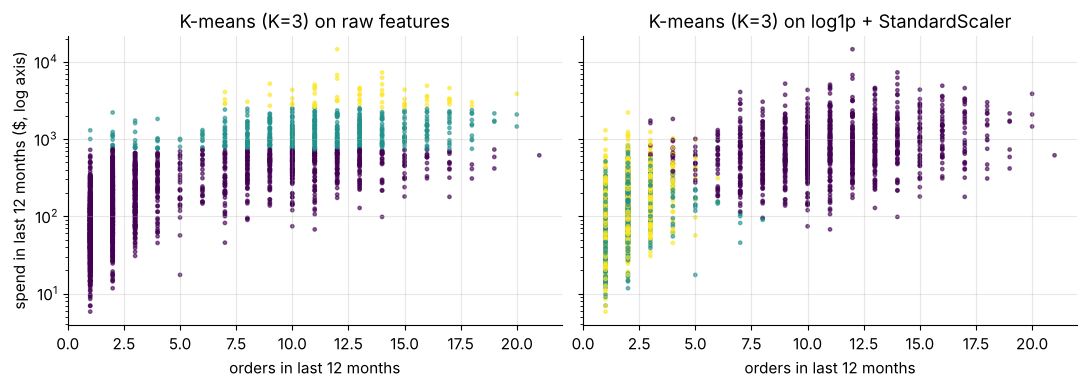

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, labels, title in [(axes[0], km_raw.labels_, "raw features"),
                          (axes[1], seg_pipe[-1].labels_, "log1p + StandardScaler")]:
    ax.scatter(cust["orders_12m"], cust["spend_12m"], c=labels, cmap="viridis", s=6, alpha=0.6)
    ax.set_yscale("log")
    ax.set_xlabel("orders in last 12 months")
    ax.set_title(f"K-means (K=3) on {title}")
axes[0].set_ylabel("spend in last 12 months ($, log axis)")
plt.tight_layout()
plt.show()

On raw features nearly all of the inertia comes from `spend_12m`: the three clusters are
horizontal bands of spend (light, medium, heavy spenders), and the order count and recency barely
matter. After `log1p` and standardization every feature has a say: frequent buyers form one
cluster, and the light buyers are split by recency, which this plot does not show (that is why the
two light-buyer clusters overlap here). The clusters also line up much better with the hidden
engagement flag (compare the two ARI values).

### 2.3 Taming skew and outliers: `log1p`, winsorizing, Standard vs Robust scaling

* **`log1p`**: $x \mapsto \ln(1 + x)$. It is defined at $x = 0$ (customers with zero spend) and
  turns *ratios* into *differences*: going from \$100 to \$1,000 moves a customer about as far as
  going from \$10 to \$100. Use it for counts and money, which are non-negative and right-skewed.
* **Winsorizing at the 99th percentile**: learn the cap $u_j$ = 99th percentile of feature $j$ on the
  training data, then replace $x_j$ by $\min(x_j, u_j)$. A handful of extreme accounts can no longer
  pull a centroid toward themselves.
* **`StandardScaler`**: $z = (x - \mu)/\sigma$ with mean $\mu$ and standard deviation $\sigma$
  learned on the training data. Both $\mu$ and $\sigma$ are themselves sensitive to outliers.
* **`RobustScaler`**: $z = (x - \text{median})/\text{IQR}$, where IQR is the interquartile range
  $Q_3 - Q_1$. A few extreme values barely move the median or the IQR.

The demo adds **one** wholesale-sized account (\$250,000 of spend) to the 3,000 customers and
looks at how four ordinary customers get scaled.

In [16]:
typical = pd.DataFrame({"spend_12m": [40.0, 120.0, 300.0, 900.0]})
train_spend = cust[["spend_12m"]]
with_whale = pd.concat([train_spend, pd.DataFrame({"spend_12m": [250_000.0]})], ignore_index=True)
rows = {}
for scaler_name, make_scaler in [("StandardScaler", StandardScaler), ("RobustScaler", RobustScaler)]:
    for data_name, data in [("3,000 customers", train_spend), ("+ one $250k account", with_whale)]:
        scaled = make_scaler().fit(data).transform(typical).ravel()
        rows[(scaler_name, data_name)] = dict(zip(["$40", "$120", "$300", "$900"], scaled))
print("scaled values of four ordinary customers:")
print(pd.DataFrame(rows).T.round(3))

scaled values of four ordinary customers:
                                      $40   $120   $300   $900
StandardScaler 3,000 customers     -0.584 -0.475 -0.229  0.591
               + one $250k account -0.111 -0.093 -0.054  0.076
RobustScaler   3,000 customers     -0.338 -0.171  0.205  1.459
               + one $250k account -0.338 -0.172  0.204  1.456


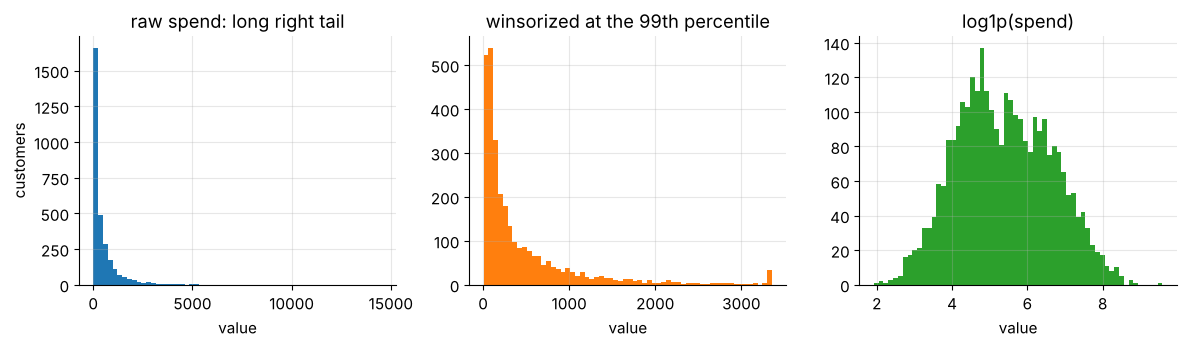

99th percentile cap learned on the training data: $3,356.63


In [17]:
from sklearn.base import BaseEstimator, TransformerMixin


class Winsorizer(BaseEstimator, TransformerMixin):
    """Cap every column at its q-quantile learned on the training data (fit), then clip (transform)."""

    def __init__(self, q: float = 0.99):
        self.q = q

    def fit(self, X, y=None):
        self.upper_ = np.quantile(np.asarray(X, dtype=float), self.q, axis=0)
        return self

    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.upper_)


fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
spend = cust["spend_12m"].to_numpy()
axes[0].hist(spend, bins=60, color="C0")
axes[0].set_title("raw spend: long right tail")
axes[1].hist(Winsorizer(0.99).fit(spend[:, None]).transform(spend[:, None]).ravel(), bins=60, color="C1")
axes[1].set_title("winsorized at the 99th percentile")
axes[2].hist(np.log1p(spend), bins=60, color="C2")
axes[2].set_title("log1p(spend)")
for ax in axes:
    ax.set_xlabel("value")
axes[0].set_ylabel("customers")
plt.tight_layout()
plt.show()
print(f"99th percentile cap learned on the training data: ${np.quantile(spend, 0.99):,.2f}")

With the whale in the training data, `StandardScaler` squeezes the four ordinary customers almost
on top of each other: the one huge account inflates $\sigma$, so ordinary differences shrink.
`RobustScaler` hardly notices it. That is why §4 tries a *winsorize → log1p → RobustScaler* pipeline
next to the plain *log1p → StandardScaler* one.

> **Common pitfall.** `log1p` is not a cure for everything. It needs $x > -1$ (fine for counts and
> money, wrong for profits that can be negative), and it changes what "distance" means. That is a
> modeling decision you should state, not a hidden default.

### 2.4 New customers must go through the *same fitted* pipeline

A fitted segmentation is three things learned from the training data: the transform parameters
(winsorizing caps, $\mu$ and $\sigma$, or median and IQR), the centroids **in the transformed
space**, and the mapping from cluster number to business program. A new customer is scored by
(1) transforming them with the *stored* parameters and (2) picking the nearest centroid by squared
Euclidean distance in that space. A scikit-learn `Pipeline` does both in `predict`.

Two classic deployment bugs:

1. **Raw point vs. scaled centroids.** The centroids live in standardized units (values around
   $-2$ to $2$), the raw point lives in days and dollars. The distances are meaningless and nearly
   every customer lands in whichever centroid has the largest coordinates.
2. **Refitting the scaler on the new batch.** A small batch of new customers has its own mean and
   standard deviation, so the same person gets different coordinates depending on who else is in the
   batch. Scores must never depend on the batch.

In [18]:
centers_z = seg_pipe[-1].cluster_centers_
profile = cust[feat_cols].groupby(seg_pipe[-1].labels_).median()
profile["customers"] = np.bincount(seg_pipe[-1].labels_)
print("cluster profiles (medians in original units):")
print(profile.round(1))

new_cust = pd.DataFrame({"recency_days": [20, 240, 5, 10, 60], "orders_12m": [2, 1, 14, 1, 4],
                         "spend_12m": [90.0, 45.0, 1100.0, 900.0, 300.0]},
                        index=["N1", "N2", "N3", "N4", "N5"])
right = seg_pipe.predict(new_cust)
manual = sq_dists(seg_pipe[:-1].transform(new_cust), centers_z).argmin(1)
wrong_raw = sq_dists(new_cust.to_numpy(float), centers_z).argmin(1)
print("\nscoring five new customers:")
print(pd.concat([new_cust, pd.DataFrame({"pipeline.predict": right, "manual (same transform)": manual,
                                        "WRONG: raw vs scaled centroids": wrong_raw}, index=new_cust.index)], axis=1))

# A batch that arrives after a loyalty event: six frequent, recent, high-spending customers.
event = pd.DataFrame({"recency_days": [5, 3, 8, 12, 2, 30], "orders_12m": [14, 18, 12, 16, 20, 9],
                      "spend_12m": [1100.0, 2000.0, 1500.0, 1300.0, 2600.0, 700.0]},
                     index=["E1", "E2", "E3", "E4", "E5", "E6"])
refit = StandardScaler().fit_transform(np.log1p(event.to_numpy(float)))   # WRONG: statistics of this batch
print("\nloyalty-event batch:")
print(pd.concat([event, pd.DataFrame({"pipeline.predict": seg_pipe.predict(event),
                                     "WRONG: scaler refit on the batch": sq_dists(refit, centers_z).argmin(1)},
                                    index=event.index)], axis=1))

cluster profiles (medians in original units):
   recency_days  orders_12m  spend_12m  customers
0          16.0        11.0      762.9       1047
1          26.0         2.0       98.3        714
2         145.0         2.0      114.5       1239

scoring five new customers:
    recency_days  orders_12m  spend_12m  pipeline.predict  manual (same transform)  WRONG: raw vs scaled centroids
N1            20           2       90.0                 1                        1                               0
N2           240           1       45.0                 2                        2                               2
N3             5          14     1100.0                 0                        0                               0
N4            10           1      900.0                 1                        1                               0
N5            60           4      300.0                 2                        2                               0

loyalty-event batch:
    recency_d

Reading the outputs:

* The three clusters are *frequent regulars* (cluster 0: about 11 orders and \$760 in the median),
  *recent light buyers* (cluster 1) and *lapsing light buyers* (cluster 2, median recency about
  145 days).
* **Raw vs. scaled centroids:** N1, N4 and N5 all land in cluster 0. Raw values such as 60 days or
  \$300 are huge compared with standardized coordinates, so the winner is simply the centroid
  whose coordinates point most in the direction of "big numbers".
* **Refitting on the batch:** every customer in the loyalty-event batch is a frequent regular, and
  the correctly fitted pipeline says so. Refit on the batch, and four of the six are scattered into
  the light-buyer clusters, because standardization now only says "below or above *this batch's*
  average".

> **Key idea.** Fit every learned transformation (caps, means, standard deviations, medians,
> IQRs, centroids) **once** on the training data. Store the fitted pipeline and use it to score
> every later customer, one at a time or in batches. The answer must not depend on who else is
> in the batch.

### ✏️ Exercise 3: which feature dominates the inertia?

Write `dominant_feature(Z, centers, labels)` that returns `(j, share)`: the index of the feature
with the largest share of the total within-cluster squared distance, and that share. We will use
a close cousin of this quantity in §4 as a screening criterion ("no single feature may control
more than a set fraction of the squared distances").

In [19]:
# ✏️ Exercise 3: feature dominance
def dominant_feature(Z, centers, labels):
    """Return (j, share_j) for the feature with the largest share of sum_i ||z_i - c_{a(i)}||^2."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex3():
    Zt = np.array([[0.0, 0.0], [2.0, 1.0], [10.0, 10.0], [10.0, 13.0]])
    Ct = np.array([[1.0, 0.5], [10.0, 11.5]])
    j, share = dominant_feature(Zt, Ct, np.array([0, 0, 1, 1]))
    # per-feature sums: feature 0 -> 1 + 1 + 0 + 0 = 2, feature 1 -> 0.25 + 0.25 + 2.25 + 2.25 = 5
    assert int(j) == 1 and np.isclose(share, 5 / 7), f"got ({j}, {share})"
    j2, s2 = dominant_feature(cust[feat_cols].to_numpy(), km_raw.cluster_centers_, km_raw.labels_)
    assert int(j2) == 2 and s2 > 0.9, "on the raw customer data, spend (column 2) should dominate"


run_check("Exercise 3", _test_ex3)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def dominant_feature(Z, centers, labels):
    per_feature = ((np.asarray(Z) - centers[labels]) ** 2).sum(axis=0)
    shares = per_feature / per_feature.sum()
    j = int(shares.argmax())
    return j, shares[j]
```
Each point is compared with *its own* centroid (`centers[labels]`), the squared differences are
summed down the rows, and the column sums are normalized to shares.
</details>

### ✏️ Exercise 4: robust scaling, fitted on train only

Write `robust_scale(X_train, X_new)` that learns the per-column median and IQR
($Q_3 - Q_1$, the 75th minus the 25th percentile) on `X_train` and returns the scaled `X_new`.
It must agree with `RobustScaler().fit(X_train).transform(X_new)`.

In [20]:
# ✏️ Exercise 4: robust scaling with training statistics
def robust_scale(X_train, X_new):
    """(X_new - median(X_train)) / IQR(X_train), column by column."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex4():
    Xt = cust[feat_cols].to_numpy(float)
    Xn = new_cust.to_numpy(float)
    got = robust_scale(Xt, Xn)
    want = RobustScaler().fit(Xt).transform(Xn)
    assert np.allclose(got, want), "does not match RobustScaler fitted on X_train"
    got_whale = robust_scale(with_whale.to_numpy(float), typical.to_numpy(float))
    assert np.allclose(got_whale.ravel(), [-0.338, -0.172, 0.204, 1.456], atol=2e-3), \
        "scaled typical customers should barely move when a whale is added"


run_check("Exercise 4", _test_ex4)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def robust_scale(X_train, X_new):
    q1, med, q3 = np.percentile(X_train, [25, 50, 75], axis=0)
    return (np.asarray(X_new, float) - med) / (q3 - q1)
```
All three statistics come from `X_train`, and `X_new` is only transformed. (A production version
would also guard against an IQR of zero, which `RobustScaler` handles by leaving that column
unscaled.)
</details>

---
## 3. Business rules before clustering: concentration (HHI) routing

Clustering answers "which customers look alike?". It does **not** answer "which customers belong in
this model at all?". Some accounts follow a different business process (a wholesale reseller has
an account manager, invoices and bulk prices), and if you let them into a retail K-means they pull
centroids toward themselves and stretch every scaler. Such accounts should be **routed out by an
explicit rule before clustering**, and the rule should be cheap, interpretable and auditable.

### 3.1 The data: a synthetic transaction log

For the rest of the notebook's customer work we generate a realistic order history for an online
store: 6,000 retail customers and 110 wholesale accounts, from 2022-07-01 to 2024-12-31 (915 days).
Every retail customer secretly belongs to one of six *archetypes* (regular, seasonal, frequent
returner, one-time buyer, VIP, occasional). Wholesale accounts buy a few core products in bulk.
Real data never comes with these labels. We keep them only to check what our methods recover.

How the simulation works:

* each customer's first order falls on a random day (more sign-ups in the holiday months).
* repeat orders arrive as a Poisson process whose personal rate is drawn around the archetype's
  rate, during a random active lifetime, modulated by the season (seasonal shoppers buy almost only
  from mid-October to December), and we generate it by *thinning* (draw candidate times at the
  maximum rate, keep each with probability intensity/maximum).
* each order has 1 + Poisson extra line items. Products are drawn from a long-tailed popularity
  curve. Wholesale lines use the account's three core products and quantities around 50.
* each customer has a personal return probability (high for frequent returners).

In [21]:
START, END = pd.Timestamp("2022-07-01"), pd.Timestamp("2024-12-31")
N_DAYS = (END - START).days + 1                      # 915 days of history
DAY_DATES = pd.date_range(START, END, freq="D")      # day index -> calendar date
MONTH_WEIGHT = np.array([0.8, 0.8, 0.9, 0.9, 1.0, 0.9, 0.9, 0.9, 1.0, 1.1, 1.6, 1.8])  # Jan..Dec

ARCHETYPES = pd.DataFrame(
    {   # share of retail customers, repeat orders per month, mean active life (days),
        # mean extra lines per order, Beta(a, b) distribution of the personal return probability
        "share":       [0.26, 0.18, 0.12, 0.30, 0.06, 0.08],
        "per_month":   [0.9, 0.3, 1.4, 0.0, 2.2, 0.25],
        "life_days":   [700, 900, 600, 0, 900, 600],
        "extra_lines": [1.3, 1.5, 1.6, 1.0, 3.5, 1.2],
        "ret_a":       [1, 1, 8, 1, 1, 1],
        "ret_b":       [24, 24, 8, 30, 30, 30],
    },
    index=["regular", "seasonal", "returner", "one_time", "vip", "occasional"],
)


def day_intensity(day: np.ndarray, archetype: str) -> np.ndarray:
    """Relative purchase intensity on each day index (seasonality)."""
    dates = DAY_DATES[day]
    if archetype == "seasonal":                       # buys mostly from mid-October to December
        return np.where(dates.dayofyear >= 288, 4.0, 0.08)
    return MONTH_WEIGHT[dates.month - 1]

In [22]:
def simulate_orders(rng, n_retail=6000, n_b2b=110) -> pd.DataFrame:
    """One row per order: order_id, customer_id, day, archetype, returned, date."""
    names = ARCHETYPES.index.to_numpy()
    arche = rng.choice(len(names), size=n_retail, p=ARCHETYPES["share"] / ARCHETYPES["share"].sum())
    w = day_intensity(np.arange(N_DAYS), "regular")
    first_day = rng.choice(N_DAYS, size=n_retail, p=w / w.sum())
    days, owners = [first_day], [np.arange(n_retail)]               # every customer's first order
    for k, name in enumerate(names):                                # repeat orders, archetype by archetype
        idx = np.flatnonzero(arche == k)
        rate, life = ARCHETYPES.loc[name, ["per_month", "life_days"]]
        if rate == 0:
            continue
        lam = rng.gamma(4.0, rate / 4.0, size=idx.size) / 30.44     # personal orders per day
        stop = np.minimum(first_day[idx] + rng.exponential(life, idx.size), N_DAYS - 1)
        span = np.maximum(stop - first_day[idx], 0)
        top = 4.0 if name == "seasonal" else MONTH_WEIGHT.max()     # maximum of day_intensity
        n_cand = rng.poisson(lam * span * top)                      # candidate orders before thinning
        local = np.repeat(np.arange(idx.size), n_cand)
        t = (first_day[idx][local] + rng.uniform(0, 1, local.size) * span[local]).astype(int)
        keep = rng.uniform(0, top, t.size) < day_intensity(t, name)  # thinning
        days.append(t[keep]); owners.append(idx[local][keep])
    # wholesale (B2B) accounts: steady bulk buyers
    b_ids = n_retail + np.arange(n_b2b)
    b_first = rng.integers(0, 600, n_b2b)
    b_span = N_DAYS - 1 - b_first
    b_n = rng.poisson(rng.gamma(4.0, 1.2 / 4.0, n_b2b) / 30.44 * b_span)
    b_own = np.repeat(np.arange(n_b2b), b_n)
    b_t = (b_first[b_own] + rng.uniform(0, 1, b_own.size) * b_span[b_own]).astype(int)
    days += [b_first, b_t]; owners += [b_ids, b_ids[b_own]]
    day, cust = np.concatenate(days), np.concatenate(owners)
    order = np.lexsort((cust, day))
    orders = pd.DataFrame({"customer_id": cust[order], "day": day[order]})
    orders.insert(0, "order_id", np.arange(len(orders)))
    labels = np.concatenate([names[arche], np.repeat("b2b", n_b2b)])
    orders["archetype"] = labels[orders["customer_id"]]
    p_ret = np.concatenate([rng.beta(ARCHETYPES["ret_a"].to_numpy()[arche], ARCHETYPES["ret_b"].to_numpy()[arche]),
                            rng.beta(1, 50, n_b2b)])
    orders["returned"] = rng.uniform(size=len(orders)) < p_ret[orders["customer_id"]]
    orders["date"] = DAY_DATES[orders["day"]]
    return orders

In [23]:
def simulate_lines(rng, orders: pd.DataFrame, n_sku=600, n_retail=6000):
    """Line items (order_id, customer_id, sku, qty, unit_price, amount). Also adds order amounts."""
    price = np.round(np.exp(rng.normal(np.log(16), 0.55, n_sku)), 2)     # list price per product
    popularity = 1.0 / np.arange(1, n_sku + 1) ** 1.05                   # long-tailed popularity
    popularity /= popularity.sum()
    extra = ARCHETYPES["extra_lines"].reindex(orders["archetype"]).fillna(0.6).to_numpy()
    o_idx = np.repeat(np.arange(len(orders)), 1 + rng.poisson(extra))
    cust = orders["customer_id"].to_numpy()[o_idx]
    sku = rng.choice(n_sku, size=o_idx.size, p=popularity)
    qty = 1 + rng.poisson(0.25, o_idx.size)
    is_b2b = cust >= n_retail                                            # wholesale: core products, bulk
    core = rng.choice(n_sku, size=(cust.max() + 1 - n_retail, 3), p=popularity)
    pick = rng.choice(3, size=is_b2b.sum(), p=[0.92, 0.06, 0.02])
    sku[is_b2b] = core[cust[is_b2b] - n_retail, pick]
    qty[is_b2b] = 12 + rng.poisson(40, is_b2b.sum())
    lines = pd.DataFrame({"order_id": orders["order_id"].to_numpy()[o_idx], "customer_id": cust,
                          "sku": sku, "qty": qty, "unit_price": price[sku]})
    lines["amount"] = lines["qty"] * lines["unit_price"]
    amounts = lines.groupby("order_id")["amount"].sum().reindex(orders["order_id"]).to_numpy()
    return orders.assign(amount=amounts), lines


log_rng = np.random.default_rng(7)
orders = simulate_orders(log_rng)
orders, lines = simulate_lines(log_rng, orders)
true_type = orders.drop_duplicates("customer_id").set_index("customer_id")["archetype"]   # hidden truth
print(f"orders: {orders.shape}, line items: {lines.shape}")
print(orders.groupby("archetype").agg(customers=("customer_id", "nunique"), orders=("order_id", "size"),
                                      median_order_value=("amount", "median"),
                                      return_rate=("returned", "mean")).round(3))
print(orders[["order_id", "customer_id", "date", "amount", "returned"]].head(3).to_string(index=False))

orders: (49960, 7), line items: (140339, 6)
            customers  orders  median_order_value  return_rate
archetype                                                     
b2b               110    2831            1160.880        0.018
occasional        458    1616              38.970        0.027
one_time         1763    1763              34.640        0.036
regular          1581   17225              41.060        0.042
returner          685    9996              46.515        0.485
seasonal         1126    5465              45.230        0.039
vip               387   11064              87.175        0.031
 order_id  customer_id       date  amount  returned
        0         2255 2022-07-01   53.56     False
        1         2545 2022-07-01   52.69     False
        2         3776 2022-07-01  121.76     False


### 3.2 The Herfindahl–Hirschman index (HHI)

Take one customer's spend over a window and split it over the $n$ products they bought, with
shares $s_1, \dots, s_n \ge 0$, $\sum_i s_i = 1$. Their **concentration index** is

$$
\text{HHI} = \sum_{i=1}^{n} s_i^2 .
$$

(Economists use the same formula on market shares to measure how concentrated an industry is.)

**Range: $1/n \le \text{HHI} \le 1$.**

* *Upper bound.* Each $0 \le s_i \le 1$, so $s_i^2 \le s_i$ and $\sum_i s_i^2 \le \sum_i s_i = 1$,
  with equality only if one share is 1 and the rest are 0: all money on one product.
* *Lower bound.* Consider the spread of the shares around their average $1/n$:
  $0 \le \sum_i (s_i - \tfrac1n)^2 = \sum_i s_i^2 - \tfrac2n\sum_i s_i + \tfrac{n}{n^2} = \text{HHI} - \tfrac1n$.
  So $\text{HHI} \ge 1/n$, with equality only when every share equals $1/n$.

A handy reading is the **effective number of products** $1/\text{HHI}$: a customer with
HHI $= 0.25$ spends *as if* they split their money evenly over 4 products.

**By hand.** A retail customer spends \$600, \$200, \$150 and \$50 on four products (total \$1,000):
shares $0.6, 0.2, 0.15, 0.05$, so HHI $= 0.36 + 0.04 + 0.0225 + 0.0025 = 0.425$ and the effective
number of products is $1/0.425 \approx 2.35$. A reseller spends \$9,000, \$600 and \$400 on three
products: shares $0.9, 0.06, 0.04$ and HHI $= 0.81 + 0.0036 + 0.0016 = 0.8152$ (about 1.2 effective
products).

In [24]:
def hhi(amounts) -> float:
    """Herfindahl–Hirschman index of a vector of non-negative amounts."""
    s = np.asarray(amounts, dtype=float)
    s = s / s.sum()
    return float((s ** 2).sum())


print(f"retail example  : HHI = {hhi([600, 200, 150, 50]):.4f}  (effective products {1 / hhi([600, 200, 150, 50]):.2f})")
print(f"reseller example: HHI = {hhi([9000, 600, 400]):.4f}  (effective products {1 / hhi([9000, 600, 400]):.2f})")
print(f"bounds for n = 4: even split {hhi([1, 1, 1, 1]):.2f} = 1/4, single product {hhi([5, 0, 0, 0]):.2f}")


def spend_hhi(lines, orders, snapshot, window_days=365) -> pd.DataFrame:
    """Per-customer product-spend HHI, number of products, units and spend in the window before `snapshot`."""
    start = snapshot - pd.to_timedelta(window_days, unit="D")
    in_window = orders.loc[(orders["date"] < snapshot) & (orders["date"] >= start), "order_id"]
    li = lines[lines["order_id"].isin(in_window)]
    by_sku = li.groupby(["customer_id", "sku"]).agg(spend=("amount", "sum"), units=("qty", "sum")).reset_index()
    by_sku["share"] = by_sku["spend"] / by_sku.groupby("customer_id")["spend"].transform("sum")
    return (by_sku.assign(share_sq=by_sku["share"] ** 2)
                  .groupby("customer_id")
                  .agg(hhi=("share_sq", "sum"), n_products=("sku", "size"),
                       units=("units", "sum"), spend=("spend", "sum")))


SNAP = pd.Timestamp("2025-01-01")                 # "today": we use the 12 months before this date
conc = spend_hhi(lines, orders, SNAP)
conc["true_type"] = true_type.reindex(conc.index)
print(f"\ncustomers active in the last 12 months: {len(conc)}")
print(conc.groupby("true_type")["hhi"].describe()[["count", "25%", "50%", "75%"]].round(3))

retail example  : HHI = 0.4250  (effective products 2.35)
reseller example: HHI = 0.8152  (effective products 1.23)
bounds for n = 4: even split 0.25 = 1/4, single product 1.00

customers active in the last 12 months: 4052
             count    25%    50%    75%
true_type                              
b2b          110.0  0.757  0.887  0.983
occasional   330.0  0.198  0.327  0.504
one_time     707.0  0.502  0.591  1.000
regular     1261.0  0.095  0.142  0.251
returner     529.0  0.074  0.108  0.170
seasonal     786.0  0.146  0.225  0.375
vip          329.0  0.050  0.061  0.086


### 3.3 The routing rule, and the single-order trap

The wholesale accounts have the highest concentration (median HHI near 0.9), so the natural rule
is "**route accounts with HHI > 0.5 to the B2B process**". But look at the one-time buyers: their
median HHI is also high, and at least a quarter of them (the whole top quartile) sit at exactly 1.
Of course: a customer who placed a single order with a single product has spent 100% of their
money on one product. The index is *trivially* 1. It measures concentration, but with one or two
purchases there is nothing to concentrate. The same trap appears with any share-based feature: for
example "share of orders placed in the busiest quarter" is trivially 100% for every single-order
customer.

The fix is a **minimum-support guard**: apply the concentration rule only to accounts with enough
volume for the share to mean something. Here we require at least 40 units bought in the window
(a wholesale order alone contains about 50 units).

In [25]:
rules = {
    "HHI > 0.5": conc["hhi"] > 0.5,
    "HHI > 0.5 and units >= 40": (conc["hhi"] > 0.5) & (conc["units"] >= 40),
}
routing = pd.DataFrame({name: mask.groupby(conc["true_type"]).sum() for name, mask in rules.items()}).T
routing["total routed"] = routing.sum(axis=1)
print("accounts routed to the B2B process, by hidden true type:")
print(routing)

single = conc[(conc["true_type"] != "b2b") & (conc["hhi"] > 0.999)]
print(f"\nretail customers with HHI = 1: {len(single)}; all of them bought exactly one product: "
      f"{(single['n_products'] == 1).all()}; median units bought: {single['units'].median():.0f}")

b2b_ids = conc.index[rules["HHI > 0.5 and units >= 40"]]
missed = conc[(conc["true_type"] == "b2b") & ~conc.index.isin(b2b_ids)]
print(f"guarded rule routes {len(b2b_ids)} accounts, "
      f"{(true_type.reindex(b2b_ids) == 'b2b').mean():.0%} of them truly wholesale")
print("wholesale accounts the rule misses:")
print(missed[["hhi", "n_products", "units", "spend"]].round(3))

accounts routed to the B2B process, by hidden true type:
true_type                  b2b  occasional  one_time  regular  returner  seasonal  vip  total routed
HHI > 0.5                  109          95       569      145        26       132    3          1079
HHI > 0.5 and units >= 40  109           0         0        0         0         0    0           109

retail customers with HHI = 1: 419; all of them bought exactly one product: True; median units bought: 1
guarded rule routes 109 accounts, 100% of them truly wholesale
wholesale accounts the rule misses:
               hhi  n_products  units    spend
customer_id                                   
6053         0.489           3    324  6401.05


The unguarded rule would hand 1,079 accounts to the B2B team, and 970 of them are retail customers
(569 one-time buyers alone). With the volume guard the rule routes exactly 109 accounts, all of them
truly wholesale. One wholesale account slips through: its HHI is 0.489, just under the threshold,
because it splits its bulk orders over three products. No simple rule is perfect, but this one has
false alarms and misses one account in 110, and the miss is visible in an audit list like the one
above (a human can then decide whether to add, for example, "or more than 200 units" to the rule).

### 3.4 A behavioral segmentation for retail customers

After routing, the retail team wants programs for its established customers. We describe each
retail customer by four behavioral features computed over the 12 months before the snapshot:

| feature | definition | why it matters |
|---|---|---|
| `recency` | days since the last order | lapsing customers need a different message |
| `monthly_rate` | orders in the window ÷ months observed (tenure, capped at 12) | engagement |
| `return_rate` | returned orders ÷ orders | returns cost money (shipping, handling) |
| `peak_q_share` | share of the window's orders placed in the busiest calendar quarter | seasonality |

Two more business rules decide who is in the model: accounts routed to B2B are out, and customers
with less than 180 days of tenure go to an onboarding flow instead (their rates are not yet
meaningful). The pipeline is a `StandardScaler` followed by K-means with $K = 5$.

In [26]:
def behavior_features(orders: pd.DataFrame, snapshot: pd.Timestamp, window_days: int = 365) -> pd.DataFrame:
    """Per-customer behavioral features from the orders in the window before `snapshot`."""
    past = orders[orders["date"] < snapshot]
    first, last = past.groupby("customer_id")["date"].min(), past.groupby("customer_id")["date"].max()
    win = past[past["date"] >= snapshot - pd.to_timedelta(window_days, unit="D")]
    g = win.groupby("customer_id")
    feat = pd.DataFrame({"n_orders": g.size(), "returns": g["returned"].sum()})
    feat["tenure_days"] = (snapshot - first.reindex(feat.index)).dt.days
    feat["recency"] = (snapshot - last.reindex(feat.index)).dt.days
    feat["monthly_rate"] = feat["n_orders"] / (feat["tenure_days"] / 30.44).clip(1, 12)
    feat["return_rate"] = feat["returns"] / feat["n_orders"]
    per_q = win.groupby(["customer_id", win["date"].dt.quarter]).size().unstack(fill_value=0)
    feat["peak_q_share"] = (per_q.max(axis=1) / per_q.sum(axis=1)).reindex(feat.index)
    return feat


beh = behavior_features(orders, SNAP)
retail_pop = beh[~beh.index.isin(b2b_ids) & (beh["tenure_days"] >= 180)].copy()
beh_cols = ["recency", "monthly_rate", "return_rate", "peak_q_share"]
print(f"active in window: {len(beh)} | routed to B2B: {beh.index.isin(b2b_ids).sum()} | "
      f"onboarding (tenure < 180 d): {(~beh.index.isin(b2b_ids) & (beh['tenure_days'] < 180)).sum()} | "
      f"retail model population: {len(retail_pop)}")

behavior_seg = Pipeline([("scale", StandardScaler()),
                         ("km", KMeans(n_clusters=5, n_init=10, random_state=0))]).fit(retail_pop[beh_cols])
retail_pop["cluster"] = behavior_seg.predict(retail_pop[beh_cols])
prof = retail_pop.groupby("cluster")[beh_cols].median()
prof["mean_return_rate"] = retail_pop.groupby("cluster")["return_rate"].mean()
prof["median_orders"] = retail_pop.groupby("cluster")["n_orders"].median()
prof["share_single_order"] = retail_pop.groupby("cluster")["n_orders"].apply(lambda s: (s == 1).mean())
prof["size"] = retail_pop["cluster"].value_counts().sort_index()
print("\ncluster profiles (medians unless stated):")
print(prof.round(3))
print("\nhidden true types inside each cluster:")
print(pd.crosstab(retail_pop["cluster"], true_type.reindex(retail_pop.index)))

active in window: 4052 | routed to B2B: 109 | onboarding (tenure < 180 d): 1369 | retail model population: 2574

cluster profiles (medians unless stated):
         recency  monthly_rate  return_rate  peak_q_share  mean_return_rate  median_orders  share_single_order  size
cluster                                                                                                             
0            8.0         2.333        0.034         0.391             0.091           26.0               0.000   255
1          280.0         0.120        0.000         1.000             0.021            1.0               0.703   683
2           17.0         0.333        0.000         1.000             0.019            4.0               0.191   430
3           27.0         0.667        0.000         0.500             0.044            7.0               0.000   960
4           31.0         0.870        0.625         0.500             0.651            9.0               0.098   246

hidden true types inside 

**Read the whole profile before naming a cluster.** Clusters 1 and 2 *both* have a median
`peak_q_share` of 1.0, so a quick look at that one column would call both "seasonal". The rest of
the profile tells two different stories:

* cluster 2: median 4 orders, last order about two weeks before the snapshot (just after the holiday
  season), and the hidden labels confirm it is mostly seasonal shoppers.
* cluster 1: median recency of 280 days and **70% single-order customers**, whose
  `peak_q_share` is 1.0 *trivially* (one order is always 100% in its quarter). These are lapsed
  one-time and occasional buyers, and a "pre-season reminder" sent to them would be a guess.

The other clusters are clear: cluster 0 is the very engaged core (over two orders a month),
cluster 3 the steady regulars, and cluster 4 the frequent returners (median return rate above 0.6).

We store the cluster → program mapping **with** the model. Cluster numbers are arbitrary (a
different seed would permute them), so we derive the mapping from the profile with explicit rules
that encode the reading above. If the data ever change so much that the rules no longer make
sense, the assertion fails loudly instead of silently mislabeling customers.

In [27]:
def map_programs(prof: pd.DataFrame) -> dict:
    """Cluster id -> program, decided from the whole profile (not from a single column)."""
    programs = {
        prof["monthly_rate"].idxmax(): "VIP perks and early access",
        prof["recency"].idxmax(): "low-cost win-back email",
        prof["mean_return_rate"].idxmax(): "returns reduction (fit guide, no free-return promos)",
    }
    rest = [k for k in prof.index if k not in programs]
    # seasonal = high peak-quarter share that is NOT explained by single orders
    seasonal = (prof.loc[rest, "peak_q_share"] * (1 - prof.loc[rest, "share_single_order"])).idxmax()
    programs[seasonal] = "pre-season reminder in October"
    for k in rest:
        programs.setdefault(k, "standard newsletter and cross-sell")
    assert len(set(programs.values())) == len(prof), "profile no longer separates the five programs"
    return dict(sorted(programs.items()))


PROGRAMS = map_programs(prof)
for k, v in PROGRAMS.items():
    print(f"cluster {k} -> {v}")

cluster 0 -> VIP perks and early access
cluster 1 -> low-cost win-back email
cluster 2 -> pre-season reminder in October
cluster 3 -> standard newsletter and cross-sell
cluster 4 -> returns reduction (fit guide, no free-return promos)


### 3.5 Scoring new accounts end to end

Five accounts arrive for scoring at the snapshot. The full decision procedure is:

```text
account ──► HHI > 0.5 and units >= 40 ? ──yes──► B2B process (account manager)
                 │ no
                 ▼
           tenure < 180 days ? ──yes──► onboarding flow
                 │ no
                 ▼
           transform with the FITTED scaler ──► nearest centroid (squared Euclidean) ──► program
```

In [28]:
new_accounts = pd.DataFrame({
    "hhi": [0.27, 1.00, 0.83, 0.31, 0.22], "units": [34, 1, 1450, 6, 9],
    "tenure_days": [400, 210, 700, 800, 75], "n_orders": [11, 1, 19, 4, 3],
    "recency": [9, 210, 6, 19, 12], "return_rate": [5 / 11, 0.0, 0.0, 0.0, 1 / 3],
    "peak_q_share": [4 / 11, 1.0, 0.32, 1.0, 1.0]},
    index=["acct-101", "acct-102", "acct-103", "acct-104", "acct-105"])
new_accounts["monthly_rate"] = new_accounts["n_orders"] / (new_accounts["tenure_days"] / 30.44).clip(1, 12)

is_b2b = (new_accounts["hhi"] > 0.5) & (new_accounts["units"] >= 40)
is_onboarding = ~is_b2b & (new_accounts["tenure_days"] < 180)
in_model = ~is_b2b & ~is_onboarding

Z_new = behavior_seg[:-1].transform(new_accounts.loc[in_model, beh_cols])
D_new = sq_dists(Z_new, behavior_seg[-1].cluster_centers_)
print("squared distances to the five centroids (standardized space):")
print(pd.DataFrame(D_new, index=new_accounts.index[in_model],
                   columns=[f"c{k}" for k in range(5)]).round(2))

decision = pd.Series("", index=new_accounts.index)
decision[is_b2b] = "B2B process"
decision[is_onboarding] = "onboarding flow"
nearest = D_new.argmin(axis=1)
decision[in_model] = [f"cluster {k}: {PROGRAMS[k]}" for k in nearest]
assert np.array_equal(nearest, behavior_seg.predict(new_accounts.loc[in_model, beh_cols]))
print()
print(pd.concat([new_accounts[["hhi", "units", "tenure_days", "n_orders", "recency"]].round(2),
                 decision.rename("decision")], axis=1).to_string())

squared distances to the five centroids (standardized space):
             c0     c1    c2    c3     c4
acct-101   7.40  15.30  9.56  4.16   1.99
acct-102  17.13   0.36  2.56  6.36  14.24
acct-104  12.99   4.86  0.06  4.21  13.15

           hhi  units  tenure_days  n_orders  recency                                                         decision
acct-101  0.27     34          400        11        9  cluster 4: returns reduction (fit guide, no free-return promos)
acct-102  1.00      1          210         1      210                               cluster 1: low-cost win-back email
acct-103  0.83   1450          700        19        6                                                      B2B process
acct-104  0.31      6          800         4       19                        cluster 2: pre-season reminder in October
acct-105  0.22      9           75         3       12                                                  onboarding flow


What happened to each account:

* **acct-103** never reaches the retail model: HHI 0.83 on 1,450 units is a wholesale pattern.
* **acct-105** has only 75 days of history, so it goes to onboarding, even though its numbers could
  be pushed through the scaler. Rules about *who is in scope* come before the model.
* **acct-101** (11 orders, 5 of them returned) is nearest to the returns cluster (squared distance
  1.99 versus 4.16 for the regulars).
* **acct-102** has HHI = 1.00 and `peak_q_share` = 1.0, which look "concentrated" and "seasonal",
  but it has a single order. The guard keeps it out of B2B, and the model places it with the lapsed
  single-order customers (0.36), not with the seasonal shoppers (2.56).
* **acct-104** (4 orders, all in one quarter, last one 19 days ago) is a genuine seasonal shopper.

> **Olympiad tip.** Exam questions about deployment love the "silent" mistakes: a raw point
> compared with standardized centroids, a scaler refit on the new data, a rule that fires
> trivially (HHI = 1 for one product, 100% quarter share for one order), and a cluster named after
> one column of its profile. For each, ask: *what was fitted, on which data, and in which space is
> this distance computed?*

### ✏️ Exercise 5: HHI from line items

Write `hhi_by_customer(li)` that takes a line-item table with columns `customer_id`, `sku`,
`amount` and returns a `pd.Series` (indexed by `customer_id`) with each customer's product-spend
HHI. Several lines can belong to the same product, so aggregate per product first.

In [29]:
# ✏️ Exercise 5: HHI per customer from line items
def hhi_by_customer(li: pd.DataFrame) -> pd.Series:
    """Product-spend HHI per customer: sum over products of (product spend / total spend)^2."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex5():
    li = pd.DataFrame({"customer_id": [1, 1, 1, 1, 2, 2, 3],
                       "sku": ["a", "b", "a", "c", "x", "x", "q"],
                       "amount": [300.0, 200.0, 300.0, 200.0, 50.0, 150.0, 9.99]})
    h = hhi_by_customer(li)
    # customer 1: a=600, b=200, c=200 -> 0.36 + 0.04 + 0.04 = 0.44, customer 2: one product -> 1
    assert isinstance(h, pd.Series), "return a pandas Series"
    assert np.isclose(h.loc[1], 0.44), f"customer 1: got {h.loc[1]}"
    assert np.isclose(h.loc[2], 1.0) and np.isclose(h.loc[3], 1.0), "single-product customers have HHI = 1"
    sub = lines[lines["customer_id"].isin(conc.index[:50])]
    in_win = orders.loc[(orders["date"] < SNAP) & (orders["date"] >= SNAP - pd.to_timedelta(365, unit="D")), "order_id"]
    h2 = hhi_by_customer(sub[sub["order_id"].isin(in_win)])
    assert np.allclose(h2.sort_index(), conc["hhi"].iloc[:50].sort_index()), "does not match spend_hhi() on real data"


run_check("Exercise 5", _test_ex5)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def hhi_by_customer(li):
    per_product = li.groupby(["customer_id", "sku"])["amount"].sum()
    shares = per_product / per_product.groupby(level="customer_id").transform("sum")
    return (shares ** 2).groupby(level="customer_id").sum()
```
The first `groupby` merges repeated lines of the same product (customer 1 bought product `a`
twice), the `transform("sum")` divides by each customer's own total, and the last `groupby` sums
the squared shares.
</details>

> **Quick check.** A customer's HHI over the last year is 0.2. What is the smallest number of
> products they can have bought? Could they have bought 50?

<details>
<summary>Answer</summary>

Since HHI $\ge 1/n$, we need $n \ge 1/0.2 = 5$ products, so at least 5. Yes, 50 is possible: the
bound only limits $n$ from below. For example, 80% of the spend split evenly over 4 products
($4 \times 0.2^2 = 0.16$) plus the remaining 20% spread thinly over 46 more
($46 \times (0.2/46)^2 \approx 0.0009$) gives HHI $\approx 0.161$. Making the split a bit less
even pushes it up to exactly 0.2. The *effective* number of products would be $1/0.2 = 5$.
</details>

---
## 4. Case study: RFM segmentation you can defend

**RFM** is the classic way to summarize a customer's purchase history with three numbers:

* **Recency** $R$: days from the customer's last order to the snapshot date (smaller is better).
* **Frequency** $F$: number of orders in the 365 days before the snapshot.
* **Monetary** $M$: total spend in those 365 days.

The question for this section is not "can we run K-means on RFM?" (one line of code) but
"**which** preprocessing and **which** $K$ should the company deploy, and how do we justify the
choice to someone who will spend money on it?" We answer it the way a careful analyst would:
write the criteria first, compute them for every candidate configuration, and pick the simplest
configuration that passes.

### 4.1 Two snapshots

A **snapshot** freezes "what we knew on date $T$": only orders strictly before $T$ are used.
We take two:

* $T_1$ = 2024-01-01, the **training snapshot**: fit the pipelines (scalers and centroids) here.
* $T_2$ = 2025-01-01, one year later, the **evaluation snapshot**: score customers with the
  fitted pipelines, exactly as the deployed model would, and check what still holds.

Two details matter:

* **Inactive customers.** A customer who bought before the window but not in it has
  $F = M = 0$ and $R > 365$. They are real customers (a win-back target), so they stay in the
  table, and `log1p` handles the zeros gracefully.
* **Population changes.** Customers who joined after $T_1$ appear only at $T_2$, and the
  wholesale accounts are routed out at each snapshot with the rule from §3.

In [30]:
def rfm_table(orders: pd.DataFrame, snapshot: pd.Timestamp, window_days: int = 365) -> pd.DataFrame:
    """Recency (days since last order), frequency and monetary value over the window before `snapshot`."""
    past = orders[orders["date"] < snapshot]                          # no peeking past the snapshot
    last = past.groupby("customer_id")["date"].max()
    recent = past[past["date"] >= snapshot - pd.to_timedelta(window_days, unit="D")]
    g = recent.groupby("customer_id")
    out = pd.DataFrame({"recency": (snapshot - last).dt.days})
    out["frequency"] = g["order_id"].nunique().reindex(out.index, fill_value=0)
    out["monetary"] = g["amount"].sum().reindex(out.index, fill_value=0.0)
    return out


def retail_rfm(snapshot: pd.Timestamp) -> pd.DataFrame:
    """RFM table at `snapshot`, after routing out concentrated high-volume (B2B) accounts."""
    c = spend_hhi(lines, orders, snapshot)
    routed = c.index[(c["hhi"] > 0.5) & (c["units"] >= 40)]
    r = rfm_table(orders, snapshot)
    return r[~r.index.isin(routed)]


T1, T2 = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-01-01")
rfm_tr, rfm_ev = retail_rfm(T1), retail_rfm(T2)
rfm_cols = ["recency", "frequency", "monetary"]
print(f"training snapshot {T1.date()}: {len(rfm_tr)} customers, {(rfm_tr['frequency'] == 0).sum()} inactive in the window")
print(f"evaluation snapshot {T2.date()}: {len(rfm_ev)} customers, {(rfm_ev['frequency'] == 0).sum()} inactive, "
      f"{(~rfm_ev.index.isin(rfm_tr.index)).sum()} new since T1")
print(f"wholesale accounts left in the tables: {(true_type.reindex(rfm_ev.index) == 'b2b').sum()} (eval), "
      f"{(true_type.reindex(rfm_tr.index) == 'b2b').sum()} (train)")
print(rfm_tr.describe(percentiles=[0.5, 0.99]).round(1).T)

training snapshot 2024-01-01: 3602 customers, 618 inactive in the window
evaluation snapshot 2025-01-01: 6001 customers, 2058 inactive, 2399 new since T1
wholesale accounts left in the tables: 1 (eval), 0 (train)


            count   mean    std  min   50%     99%     max
recency    3602.0  143.2  162.9  1.0  50.5   524.0   546.0
frequency  3602.0    4.8    7.1  0.0   2.0    34.0    65.0
monetary   3602.0  289.0  555.5  0.0  91.8  2953.5  5878.6


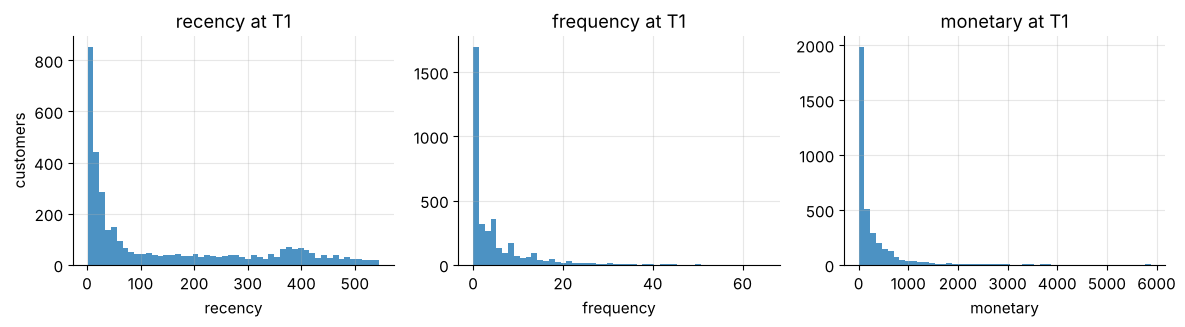

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col in zip(axes, rfm_cols):
    ax.hist(rfm_tr[col], bins=50, color="C0", alpha=0.8)
    ax.set_title(f"{col} at T1")
    ax.set_xlabel(col)
axes[0].set_ylabel("customers")
plt.tight_layout()
plt.show()

Three things to notice in the training table: monetary value is strongly right-skewed (mean about
\$289, median about \$92), frequency is a small count, and recency is bimodal (recent buyers versus
inactive customers beyond 365 days). In raw units the monetary column will dominate
every distance, as in §2.

### 4.2 Nine candidate configurations

We compare three preprocessing pipelines, each applied to all three RFM columns, with
$K \in \{3, 4, 5\}$:

| code | pipeline | idea |
|---|---|---|
| **R** | raw values | the baseline everybody tries first |
| **L** | `log1p` → `StandardScaler` | tame skew, then equalize spreads |
| **W** | winsorize at the 99th percentile → `log1p` → `RobustScaler` | also cap extremes, with median/IQR scaling |

Every pipeline is fitted on the $T_1$ table only, then used to score the $T_2$ table.

In [32]:
def make_prep(variant: str):
    """Preprocessing for one of the three variants: 'R' (raw), 'L' (log+std), 'W' (winsorize+log+robust)."""
    if variant == "R":
        return FunctionTransformer()                                     # identity
    if variant == "L":
        return Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())])
    return Pipeline([("win", Winsorizer(0.99)), ("log", FunctionTransformer(np.log1p)),
                     ("scale", RobustScaler())])


def make_model(variant: str, K: int, n_init: int = 10, seed: int = 0) -> Pipeline:
    return Pipeline([("prep", make_prep(variant)), ("km", KMeans(n_clusters=K, n_init=n_init, random_state=seed))])


X_tr, X_ev = rfm_tr[rfm_cols].to_numpy(float), rfm_ev[rfm_cols].to_numpy(float)
demo = {v: make_model(v, 4).fit(X_tr) for v in "RLW"}
for v, model in demo.items():
    sizes = np.bincount(model.predict(X_ev), minlength=4) / len(X_ev)
    print(f"{v}4: cluster shares at T2 = {np.round(sizes, 3).tolist()}")

R4: cluster shares at T2 = [0.45, 0.021, 0.108, 0.421]
L4: cluster shares at T2 = [0.229, 0.343, 0.225, 0.202]
W4: cluster shares at T2 = [0.235, 0.195, 0.343, 0.227]


Already a warning sign: the raw model puts a tiny fraction of customers in one cluster (a handful
of very large spenders). A "segment" of that size cannot carry a marketing program, and, as we
will see, it is not even stable.

**What do the classic diagnostics say?** Here are the elbow and silhouette curves of §1.6 for the
two log pipelines on the $T_1$ customers.

L: inertia [4444, 2611, 1796, 1374, 1114, 968, 842] | silhouette [0.486, 0.507, 0.484, 0.486, 0.476, 0.469, 0.463]


W: inertia [2360, 1158, 802, 630, 515, 437, 386] | silhouette [0.487, 0.545, 0.494, 0.47, 0.47, 0.47, 0.458]


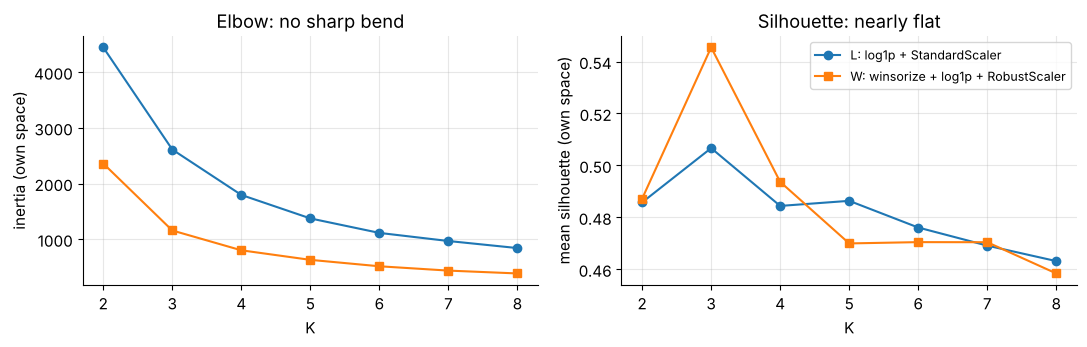

In [33]:
Ks_rfm = list(range(2, 9))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for v, marker, name in [("L", "o", "L: log1p + StandardScaler"), ("W", "s", "W: winsorize + log1p + RobustScaler")]:
    Z_tr = make_prep(v).fit_transform(X_tr)
    fits = [KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z_tr) for K in Ks_rfm]
    axes[0].plot(Ks_rfm, [f.inertia_ for f in fits], marker + "-", label=name)
    sil_curve = [silhouette_score(Z_tr, f.labels_) for f in fits]
    axes[1].plot(Ks_rfm, sil_curve, marker + "-", label=name)
    print(f"{v}: inertia {[round(f.inertia_) for f in fits]} | silhouette {np.round(sil_curve, 3).tolist()}")
axes[0].set_xlabel("K")
axes[0].set_ylabel("inertia (own space)")
axes[0].set_title("Elbow: no sharp bend")
axes[1].set_xlabel("K")
axes[1].set_ylabel("mean silhouette (own space)")
axes[1].set_title("Silhouette: nearly flat")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

Neither curve gives a crisp answer, which is typical of real customer data: inertia falls smoothly
with no sharp elbow, and the silhouettes stay within a narrow band (both peak at $K = 3$: L at
0.507, barely above its neighbors, W at 0.545). Note also that the two inertia curves cannot be
compared with each other: W's inertia is roughly half of L's at every $K$ only because
`RobustScaler` divides by the IQR instead of the standard deviation. A different ruler, not a
better clustering. We need criteria that reflect how the segmentation will be *used*.

### 4.3 Measuring agreement between two clusterings: the adjusted Rand index

Stability questions ("do I get the same clusters with another seed? another sample? next year?")
need a way to compare two labelings of the same customers. Cluster *numbers* are arbitrary, so we
compare **pairs**: for every pair of customers, are they together in labeling $U$? Together in $V$?

Let $n_{ij}$ be the number of customers in cluster $i$ of $U$ and cluster $j$ of $V$ (the
contingency table), with row sums $a_i$, column sums $b_j$ and $n$ customers in total. The number of
pairs that are together in both labelings is $\sum_{ij}\binom{n_{ij}}{2}$. Under random labelings
with the same cluster sizes its expected value is $\sum_i\binom{a_i}{2}\sum_j\binom{b_j}{2}/\binom{n}{2}$.
The **adjusted Rand index** rescales so that identical partitions score 1 and random ones score 0
on average:

$$
\text{ARI} = \frac{\sum_{ij}\binom{n_{ij}}{2} - \dfrac{\sum_i\binom{a_i}{2}\sum_j\binom{b_j}{2}}{\binom{n}{2}}}
{\tfrac12\Big[\sum_i\binom{a_i}{2} + \sum_j\binom{b_j}{2}\Big] - \dfrac{\sum_i\binom{a_i}{2}\sum_j\binom{b_j}{2}}{\binom{n}{2}}} .
$$

**By hand.** Six customers, $U = (0,0,0,1,1,1)$ and $V = (1,1,0,0,2,2)$. The contingency table is

| | $V=0$ | $V=1$ | $V=2$ | row sum $a_i$ |
|---|---|---|---|---|
| $U=0$ | 1 | 2 | 0 | 3 |
| $U=1$ | 1 | 0 | 2 | 3 |
| column sum $b_j$ | 2 | 2 | 2 | $n = 6$ |

$\sum\binom{n_{ij}}{2} = 1 + 1 = 2$, $\sum\binom{a_i}{2} = 3 + 3 = 6$, and $\sum\binom{b_j}{2} = 1+1+1 = 3$.
$\binom{6}{2} = 15$. Expected index $= 6 \cdot 3/15 = 1.2$, maximum index $= (6+3)/2 = 4.5$, so
$\text{ARI} = (2 - 1.2)/(4.5 - 1.2) = 0.8/3.3 \approx 0.242$.

Why "adjusted"? The plain Rand index counts *all* agreeing pairs (together-together and
apart-apart): here $2 + 8 = 10$ of 15 pairs, $0.667$, which sounds good for two labelings that
share little. With many small clusters, almost every pair is "apart" in both labelings, so the
plain index is close to 1 even for random labels. The adjustment removes that chance level.

In [34]:
U_demo, V_demo = np.array([0, 0, 0, 1, 1, 1]), np.array([1, 1, 0, 0, 2, 2])
print(f"ARI by hand ≈ 0.242 | sklearn: {adjusted_rand_score(U_demo, V_demo):.3f}")
print(f"relabeling V (0->2, 1->0, 2->1) does not matter: {adjusted_rand_score(U_demo, (V_demo + 2) % 3):.3f}")

chance_rng = np.random.default_rng(1)
rand_pairs = [adjusted_rand_score(chance_rng.integers(0, 4, 2000), chance_rng.integers(0, 4, 2000)) for _ in range(200)]
print(f"two random 4-cluster labelings of 2,000 customers: mean ARI {np.mean(rand_pairs):+.4f}, "
      f"range [{np.min(rand_pairs):+.4f}, {np.max(rand_pairs):+.4f}]")

ARI by hand ≈ 0.242 | sklearn: 0.242
relabeling V (0->2, 1->0, 2->1) does not matter: 0.242


two random 4-cluster labelings of 2,000 customers: mean ARI -0.0001, range [-0.0014, +0.0041]


### 4.4 The screening metrics

For each configuration we fit a **reference model** on $T_1$ (10 starts) and score the $T_2$
customers with it. Then we measure:

1. **Init-ARI (algorithmic stability).** Fit the same configuration 10 times with a *single*
   k-means++ start each (different random seeds, identical data) and average the ARI over all 45
   pairs of runs. Low values mean the objective has several competing local minima: which
   clustering you deploy would depend on luck.
2. **Bootstrap ARI, 5th percentile (sampling stability).** Refit on 30 bootstrap resamples of the
   $T_1$ customers (draw $m$ customers *with replacement*) and compare each refit's labels on $T_2$
   with the reference labels. We report the 5th percentile, not the mean: a segmentation that is
   usually stable but occasionally reshuffles is not safe to build programs on. (All nine
   configurations use the *same* 30 resamples, so differences between them are not resampling luck.)
3. **Smallest cluster.** The 5th percentile, over the bootstrap refits, of the smallest cluster's
   share of customers. A program needs enough customers to be worth running and measuring.
4. **Feature dominance.** The largest single-feature share of all pairwise squared distances in
   the transformed space. Expanding the square shows that, feature by feature,

$$
\sum_{i<l}\,(z_{ij} - z_{lj})^2 \;=\; m\sum_{i=1}^{m}(z_{ij} - \bar z_j)^2 ,
$$

   (sum $z_{ij}^2 - 2z_{ij}z_{lj} + z_{lj}^2$ over all ordered pairs to get $2m\sum_i z_{ij}^2 - 2(\sum_i z_{ij})^2$,
   then halve), so the share of pairwise squared distances is simply each feature's share of the
   total sum of squares. If one feature holds most of it, the "RFM" segmentation is really a
   one-feature segmentation.
5. **Silhouette, native and common.** *Native*: computed in the configuration's own transformed
   space. *Common*: every configuration's $T_2$ labels evaluated in **one shared space** (`log1p` +
   `StandardScaler` fitted on $T_1$). Native silhouettes are not comparable across preprocessings,
   because each pipeline measures distance with a different ruler (§4.6).
6. **Temporal ARI.** Compare the $T_2$ labels from the deployed ($T_1$-fitted) model with the labels
   from the same configuration *refit* on $T_2$. High values mean the structure found last year still
   describes this year's customers.

In [35]:
def max_feature_share(Z) -> tuple[float, int]:
    """Largest per-feature share of all pairwise squared distances (= share of the total sum of squares)."""
    Z = np.asarray(Z, dtype=float)
    ss = ((Z - Z.mean(axis=0)) ** 2).sum(axis=0)
    return float(ss.max() / ss.sum()), int(ss.argmax())


# Check the identity on a small random matrix: pairwise sums per feature vs m * sum of squares
Zc = np.random.default_rng(5).normal(size=(40, 3)) * [1.0, 3.0, 0.5]
pairwise = sum(((Zc[i] - Zc[l]) ** 2) for i in range(40) for l in range(i + 1, 40))
print("pairwise per feature :", np.round(pairwise, 3))
print("m * sum of squares   :", np.round(40 * ((Zc - Zc.mean(0)) ** 2).sum(0), 3))

common_space = make_prep("L").fit(X_tr)                  # one shared ruler for silhouettes
sil_idx = np.random.default_rng(0).choice(len(X_ev), size=2000, replace=False)   # silhouette is O(n^2)
Zev_common = common_space.transform(X_ev)[sil_idx]
boot_rng = np.random.default_rng(0)
BOOT_IDX = [boot_rng.integers(0, len(X_tr), len(X_tr)) for _ in range(30)]       # same resamples for all

pairwise per feature : [ 1380.092 11728.324   247.253]
m * sum of squares   : [ 1380.092 11728.324   247.253]


In [36]:
def screen_config(variant: str, K: int) -> dict:
    """All screening metrics for one (preprocessing, K) configuration."""
    ref = make_model(variant, K, n_init=10, seed=0).fit(X_tr)
    lab_ref = ref.predict(X_ev)
    singles = [make_model(variant, K, n_init=1, seed=100 + s).fit(X_tr).predict(X_ev) for s in range(10)]
    init_ari = np.mean([adjusted_rand_score(a, b) for a, b in itertools.combinations(singles, 2)])
    boot_ari, boot_min = [], []
    for b, idx in enumerate(BOOT_IDX):
        lab_b = make_model(variant, K, n_init=4, seed=b).fit(X_tr[idx]).predict(X_ev)
        boot_ari.append(adjusted_rand_score(lab_ref, lab_b))
        boot_min.append(np.bincount(lab_b, minlength=K).min() / len(lab_b))
    Z_native = ref[:-1].transform(X_ev)
    dom, dom_j = max_feature_share(Z_native)
    refit_T2 = make_model(variant, K, n_init=10, seed=0).fit(X_ev).predict(X_ev)
    return {"config": f"{variant}{K}", "variant": variant, "K": K,
            "init_ari": init_ari, "boot_ari_q05": np.quantile(boot_ari, 0.05),
            "min_size_q05": np.quantile(boot_min, 0.05),
            "max_feat_share": dom, "dominant": rfm_cols[dom_j],
            "sil_native": silhouette_score(Z_native[sil_idx], lab_ref[sil_idx]),
            "sil_common": silhouette_score(Zev_common, lab_ref[sil_idx]),
            "temporal_ari": adjusted_rand_score(lab_ref, refit_T2),
            "sizes": np.round(np.bincount(lab_ref, minlength=K) / len(lab_ref), 3).tolist(),
            "_boot_ari": np.array(boot_ari), "_labels": lab_ref, "_model": ref}


t0 = time.perf_counter()
screen = [screen_config(v, K) for v in "RLW" for K in (3, 4, 5)]
print(f"screened 9 configurations in {time.perf_counter() - t0:.0f} s")
screen_df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in screen]).set_index("config")
print(screen_df.drop(columns=["variant", "K", "sizes"]).round(3))

screened 9 configurations in 10 s
        init_ari  boot_ari_q05  min_size_q05  max_feat_share  dominant  sil_native  sil_common  temporal_ari
config                                                                                                      
R3         0.977         0.885         0.020           0.802  monetary       0.540       0.271         0.100
R4         0.610         0.293         0.013           0.802  monetary       0.522       0.394         0.719
R5         0.757         0.896         0.008           0.802  monetary       0.516       0.380         0.711
L3         0.995         0.959         0.307           0.382  monetary       0.589       0.589         0.984
L4         0.994         0.956         0.195           0.382  monetary       0.564       0.564         0.977
L5         0.995         0.940         0.133           0.382  monetary       0.555       0.555         0.947
W3         0.997         0.971         0.306           0.510  monetary       0.632       0.583

### 4.5 Explicit screening criteria and the decision

The criteria below were written down *before* looking at the table (in a real project they go
into the analysis plan). Each one encodes a reason the business could get hurt:

| criterion | threshold | protects against |
|---|---|---|
| Init-ARI | $\ge 0.90$ | a segmentation that depends on the random seed |
| bootstrap ARI, 5th percentile | $\ge 0.80$ | a segmentation that depends on which customers happened to be sampled |
| smallest cluster (5th percentile) | $\ge 5\%$ | programs too small to run or to measure |
| max feature share of squared distances | $\le 0.60$ | a "multi-feature" model that is really one feature |
| temporal ARI | $\ge 0.85$ | a structure that no longer holds a year later |
| $K$ (budget) | $\le 4$ | the marketing team can run at most four distinct programs |

**Selection rule:** among configurations that pass *every* criterion, take the highest
common-space silhouette. If two are within 0.01 of each other, prefer the simpler pipeline
(fewer steps), then the smaller $K$.

In [37]:
CRITERIA = {"init_ari": (">=", 0.90), "boot_ari_q05": (">=", 0.80), "min_size_q05": (">=", 0.05),
            "max_feat_share": ("<=", 0.60), "temporal_ari": (">=", 0.85), "K": ("<=", 4)}
PIPELINE_STEPS = {"R": 0, "L": 2, "W": 3}                 # simplicity: number of preprocessing steps


def passes(df: pd.DataFrame, criteria: dict) -> pd.DataFrame:
    """Boolean table: does each configuration meet each criterion?"""
    out = pd.DataFrame(index=df.index)
    for col, (op, thr) in criteria.items():
        out[col] = df[col] >= thr if op == ">=" else df[col] <= thr
    out["ALL"] = out.all(axis=1)
    return out


ok = passes(screen_df, CRITERIA)
print(ok.replace({True: "pass", False: "FAIL"}))

survivors = screen_df[ok["ALL"]].copy()
best_sil = survivors["sil_common"].max()
near_best = survivors[survivors["sil_common"] >= best_sil - 0.01].copy()
near_best["steps"] = near_best["variant"].map(PIPELINE_STEPS)
chosen = near_best.sort_values(["steps", "K"]).index[0]
print(f"\nsurvivors: {list(survivors.index)} | common-space silhouette: "
      f"{survivors['sil_common'].round(3).to_dict()}")
print(f"within 0.01 of the best: {list(near_best.index)} -> chosen configuration: {chosen}")

       init_ari boot_ari_q05 min_size_q05 max_feat_share temporal_ari     K   ALL
config                                                                           
R3         pass         pass         FAIL           FAIL         FAIL  pass  FAIL
R4         FAIL         FAIL         FAIL           FAIL         FAIL  pass  FAIL
R5         FAIL         pass         FAIL           FAIL         FAIL  FAIL  FAIL
L3         pass         pass         pass           pass         pass  pass  pass
L4         pass         pass         pass           pass         pass  pass  pass
L5         pass         pass         pass           pass         pass  FAIL  FAIL
W3         pass         pass         pass           pass         pass  pass  pass
W4         pass         pass         pass           pass         FAIL  pass  FAIL
W5         pass         pass         pass           pass         FAIL  FAIL  FAIL

survivors: ['L3', 'L4', 'W3'] | common-space silhouette: {'L3': 0.589, 'L4': 0.564, 'W3': 0.583}


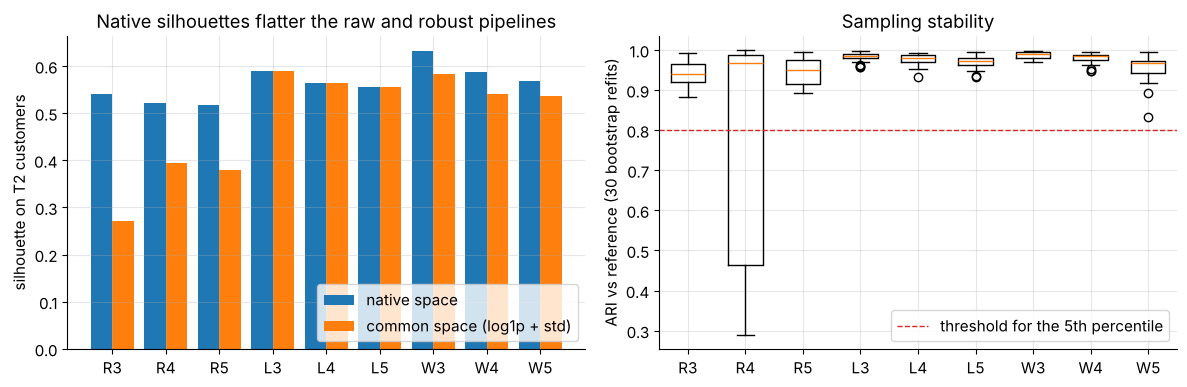

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xpos = np.arange(len(screen_df))
axes[0].bar(xpos - 0.2, screen_df["sil_native"], width=0.4, label="native space")
axes[0].bar(xpos + 0.2, screen_df["sil_common"], width=0.4, label="common space (log1p + std)")
axes[0].set_xticks(xpos, screen_df.index)
axes[0].set_ylabel("silhouette on T2 customers")
axes[0].set_title("Native silhouettes flatter the raw and robust pipelines")
axes[0].legend(loc="lower right")
axes[1].boxplot([r["_boot_ari"] for r in screen], positions=xpos, widths=0.6)
axes[1].axhline(0.80, color="C3", ls="--", lw=1, label="threshold for the 5th percentile")
axes[1].set_xticks(xpos, screen_df.index)
axes[1].set_ylabel("ARI vs reference (30 bootstrap refits)")
axes[1].set_title("Sampling stability")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.6 Reading the screening table

* **Raw (R3–R5) fails almost everything.** 80% of all squared distances come from `monetary`, so
  the clusters are spend bands. The smallest cluster holds 2% of customers or less (a few big
  spenders). R4 is unstable even across random starts (Init-ARI 0.61), and R3 does not survive a year
  (temporal ARI 0.10: refit on 2024 data, it finds completely different bands).
* **The native silhouette lies about R.** In its own space R3 scores 0.54, close to the log
  pipelines. That number only says "spend bands are well separated *in dollars*". In the common
  space, where every feature counts, R3 drops to 0.27. The same mechanism makes W3 look better than
  L3 natively (0.63 versus 0.59) although the two are essentially tied in the common space.
  Silhouettes computed with different rulers cannot be ranked against each other.
* **L3, L4 and W3 pass every criterion.** L5 and W5 exceed the four-program budget, and W4 fails
  the temporal test (0.79): refit on the 2024 customers, its four clusters are drawn noticeably
  differently from the deployed ones.
* **Decision: L3** (log1p → StandardScaler, $K = 3$), with W3 within 0.01 in the common space and
  L4 as the runner-up if the business wants a fourth program. Silhouette differences this small are
  not a strong reason to prefer one survivor. That is why the rule has a simplicity tie-break, and
  why the final judge of a segmentation is the business result of the programs built on it (§5).

> **Common pitfall.** Do not pick the configuration with the best *native* silhouette, the
> lowest inertia (it always falls as $K$ grows), or the prettiest scatter plot. Each of those can
> be gamed by the preprocessing or by $K$ itself. State criteria that reflect how the result will
> be used, compute them for every candidate, and let the rule choose.

In [39]:
best_model = next(r["_model"] for r in screen if r["config"] == chosen)
lab_ev = best_model.predict(X_ev)
seg_profile = rfm_ev.groupby(lab_ev)[rfm_cols].median()
seg_profile["mean_monetary"] = rfm_ev.groupby(lab_ev)["monetary"].mean()
seg_profile["customers"] = np.bincount(lab_ev)
seg_profile["share_of_revenue"] = rfm_ev.groupby(lab_ev)["monetary"].sum() / rfm_ev["monetary"].sum()
print(f"{chosen} segment profiles at T2 (medians unless stated):")
print(seg_profile.round(3))
print("\nhidden true types per segment (row shares):")
print(pd.crosstab(pd.Series(lab_ev, index=rfm_ev.index, name="segment"),
                  true_type.reindex(rfm_ev.index), normalize="index").round(2))

L3 segment profiles at T2 (medians unless stated):
   recency  frequency  monetary  mean_monetary  customers  share_of_revenue
0    103.0        1.0     60.72         89.378       2015             0.117
1     12.0        8.0    440.02        707.023       1925             0.883
2    588.0        0.0      0.00          0.008       2061             0.000

hidden true types per segment (row shares):
archetype  b2b  occasional  one_time  regular  returner  seasonal   vip
segment                                                                
0          0.0        0.13      0.35     0.23      0.07      0.20  0.02
1          0.0        0.04      0.00     0.41      0.20      0.20  0.15
2          0.0        0.06      0.51     0.16      0.08      0.16  0.03


### 4.7 From profiles to actions

The three L3 segments at $T_2$ read naturally (cluster numbers are arbitrary, so read the medians):

| segment | profile (medians) | share of revenue | proposed program |
|---|---|---|---|
| **engaged core** | ordered 12 days ago, 8 orders, \$440 in the year | 88% | protect: loyalty perks, early access, no blanket discounts (they buy anyway) |
| **light buyers** | about 100 days ago, 1 order, \$61 | 12% | grow: an incentive to place the next order |
| **inactive** | nearly 600 days ago, nothing in the last year | 0% | one low-cost win-back message, then stop spending |

Two honest remarks. First, the hidden labels show that each segment mixes several "true" types
(light buyers include one-time, seasonal and regular customers). RFM summarizes *recent value*, not
personality. That is fine for allocating a budget, and it is why §3 used richer behavioral
features when the programs depended on returns or seasonality. Second, a profile suggests a
program but does not prove it pays off. Is a discount for light buyers worth its cost? Would they
have bought anyway? Only an experiment can answer, which is the subject of §5.

### ✏️ Exercise 6: the adjusted Rand index from scratch

Implement `ari(u, v)` using the contingency-table formula of §4.3 (`scipy.special.comb` or
`n * (n - 1) / 2` for the binomial coefficients). Do not call `adjusted_rand_score`.

In [40]:
# ✏️ Exercise 6: adjusted Rand index
def ari(u, v) -> float:
    """Adjusted Rand index between two labelings of the same items."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex6():
    assert np.isclose(ari(U_demo, V_demo), 0.8 / 3.3), f"by-hand example: got {ari(U_demo, V_demo)}"
    assert np.isclose(ari([0, 0, 1, 1], [5, 5, 9, 9]), 1.0), "identical partitions (relabeled) must give 1"
    t_rng = np.random.default_rng(0)
    for _ in range(5):
        a, b = t_rng.integers(0, 4, 300), t_rng.integers(0, 3, 300)
        assert np.isclose(ari(a, b), adjusted_rand_score(a, b)), "does not match sklearn on random labels"
    lab_r = screen[0]["_labels"]
    assert np.isclose(ari(lab_r, lab_ev), adjusted_rand_score(lab_r, lab_ev)), "mismatch on the RFM labels"


run_check("Exercise 6", _test_ex6)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ari(u, v):
    u, v = np.asarray(u), np.asarray(v)
    _, ui = np.unique(u, return_inverse=True)
    _, vi = np.unique(v, return_inverse=True)
    table = np.zeros((ui.max() + 1, vi.max() + 1))
    np.add.at(table, (ui, vi), 1)                      # contingency table n_ij
    pairs = lambda x: x * (x - 1) / 2                   # "x choose 2", elementwise
    index = pairs(table).sum()
    sum_a, sum_b = pairs(table.sum(1)).sum(), pairs(table.sum(0)).sum()
    expected = sum_a * sum_b / pairs(len(u))
    max_index = (sum_a + sum_b) / 2
    return float((index - expected) / (max_index - expected))
```
`np.unique(..., return_inverse=True)` turns arbitrary labels (even 5 and 9) into 0, 1, 2, ...,
so the table can be filled with one `np.add.at`. (If both labelings put everything in one cluster
the denominator is 0, and scikit-learn returns 1.0 in that special case.)
</details>

### ✏️ Exercise 7: apply a screening rule

Write `pick_config(df, criteria)` that keeps the rows of a screening table meeting *every*
criterion (same format as `CRITERIA`) and returns the index of the survivor with the highest
`sil_common`, or `None` if nothing survives. (No tie-break needed here.)

In [41]:
# ✏️ Exercise 7: choose a configuration with explicit criteria
def pick_config(df: pd.DataFrame, criteria: dict):
    """Index label of the passing configuration with the highest sil_common (None if none passes)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex7():
    toy_tab = pd.DataFrame({"init_ari": [0.99, 0.95, 0.70], "temporal_ari": [0.80, 0.90, 0.99],
                            "sil_common": [0.70, 0.50, 0.90]}, index=["A3", "B3", "C4"])
    rule = {"init_ari": (">=", 0.9), "temporal_ari": (">=", 0.85)}
    assert pick_config(toy_tab, rule) == "B3", "only B3 passes both criteria"
    assert pick_config(toy_tab, {"init_ari": (">=", 0.999)}) is None, "nothing passes -> None"
    assert pick_config(screen_df, CRITERIA) == "L3", "on the RFM table the answer is L3"
    loose = dict(CRITERIA, K=("<=", 5))
    assert pick_config(screen_df, loose) == "L3", "a larger budget alone does not change the winner here"


run_check("Exercise 7", _test_ex7)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def pick_config(df, criteria):
    mask = pd.Series(True, index=df.index)
    for col, (op, thr) in criteria.items():
        mask &= (df[col] >= thr) if op == ">=" else (df[col] <= thr)
    if not mask.any():
        return None
    return df.loc[mask, "sil_common"].idxmax()
```
Combining boolean masks with `&=` keeps exactly the rows that pass every criterion.
</details>

> **Quick check.** A colleague reports: "With raw RFM and $K=3$ I get a silhouette of 0.54, almost
> as good as your 0.59, and my model has fewer steps." What do you answer?

<details>
<summary>Answer</summary>

Their 0.54 is measured in raw-dollar space, where `monetary` holds 80% of all squared distances,
so it only says that spend bands are well separated *in dollars*. Evaluated in the common space
their labels score 0.27. More importantly, the configuration fails the size, dominance and temporal
criteria: one cluster holds about 2% of customers and the structure does not survive a year.
</details>

---
## 5. Proving value: randomized experiments, uplift and incremental profit

### 5.1 Why "the customers who got the offer bought more" proves nothing

Suppose marketing sends a discount to some light buyers and later reports: *"Customers who received
the offer had a 9% purchase rate, versus 6% for everyone else. The campaign works!"* The
comparison mixes two things: the effect of the offer, and whatever made those customers different
in the first place (perhaps they were chosen *because* they looked likely to buy).

**Potential outcomes** make this precise. Every customer $i$ has two potential results over the
next 30 days: $Y_i(1)$ if treated (offer sent) and $Y_i(0)$ if not. We only ever observe one of
them. With treatment indicator $T_i \in \{0, 1\}$, the naive comparison decomposes as

$$
\underbrace{E[Y \mid T=1] - E[Y \mid T=0]}_{\text{what the report shows}}
= \underbrace{E[Y(1) - Y(0) \mid T=1]}_{\text{effect on the treated}}
+ \underbrace{E[Y(0) \mid T=1] - E[Y(0) \mid T=0]}_{\text{selection bias}} .
$$

(Add and subtract $E[Y(0)\mid T=1]$ to check it.) The selection-bias term compares the two groups
*without* any offer. It is zero only if the groups would have behaved the same, and the one design
that guarantees this is **randomization**: if a coin decides who is treated, $T$ is independent of
$(Y(0), Y(1))$, so $E[Y(0)\mid T=1] = E[Y(0)\mid T=0]$.

The randomly chosen untreated customers form the **control group**. Two quantities matter:

* **Uplift** (in percentage points): $\text{response rate}_{\text{treated}} - \text{response rate}_{\text{control}}$.
* **Incremental profit per customer**: $\overline{\text{profit}}_{\text{treated}} - \overline{\text{profit}}_{\text{control}}$,
  where profit already subtracts the discount and the contact cost.

They can disagree. A discount is paid to **every** treated buyer, including the many who would have
bought anyway, so a generous offer can raise the response rate and still lose money.

### 5.2 A simulated test on light buyers

Our synthetic store is small, so imagine the company applies the deployed L3 model to its whole
customer base and finds 90,000 light buyers. It wants to compare two offers sent by email:

| arm | discount on list price | true increase in 30-day purchase probability | contact cost |
|---|---|---|---|
| control | none (no email) | 0 | \$0 |
| strong offer | 15% | +3.0 percentage points | \$0.12 |
| weak offer | 5% | +2.0 percentage points | \$0.12 |

The gross margin is 50% of the list price, so a buyer who pays with discount $d$ yields profit
$(0.50 - d) \times$ list value, minus the contact cost. Customers live in three regions with
different baseline purchase rates (North 9%, Central 6%, South 4%), which will matter in §5.4.
Because we simulate, we know the true effects. A real company never does.

In [42]:
REGIONS = np.array(["North", "Central", "South"])
ARMS = np.array(["control", "strong", "weak"])
DISCOUNT = np.array([0.00, 0.15, 0.05])
LIFT = np.array([0.000, 0.030, 0.020])          # additive increase in purchase probability
CONTACT = np.array([0.00, 0.12, 0.12])          # $ per customer contacted
MARGIN = 0.50                                   # gross margin as a share of list price


def make_light_buyers(n: int, rng: np.random.Generator):
    """Region, personal baseline purchase probability p0 and list value of a potential order."""
    region = rng.choice(3, size=n, p=[0.30, 0.40, 0.30])
    base = np.array([0.09, 0.06, 0.04])[region]
    p0 = rng.beta(base * 20, (1 - base) * 20)                       # mean = regional base rate
    value = np.exp(rng.normal(np.log(80 * np.array([1.10, 1.00, 0.90])[region]) - 0.18, 0.6))
    return region, p0, value


def simulate_outcomes(arm, p0, value, rng):
    """Purchase indicator and profit per customer for a given arm assignment (0, 1, 2)."""
    buy = rng.uniform(size=len(arm)) < p0 + LIFT[arm]
    profit = buy * value * (MARGIN - DISCOUNT[arm]) - CONTACT[arm]
    return buy, profit


N_EXP = 90_000
region, p0, value = make_light_buyers(N_EXP, np.random.default_rng(2024))

truth = pd.DataFrame(index=ARMS)
truth["response_rate"] = [np.mean(p0 + LIFT[a]) for a in range(3)]
truth["profit_per_customer"] = [np.mean((p0 + LIFT[a]) * value * (MARGIN - DISCOUNT[a])) - CONTACT[a] for a in range(3)]
truth["uplift_pp"] = 100 * (truth["response_rate"] - truth.loc["control", "response_rate"])
truth["incremental_profit"] = truth["profit_per_customer"] - truth.loc["control", "profit_per_customer"]
print("TRUE effects in this population (known only because we simulate):")
print(truth.round(4))
print(pd.DataFrame({"customers": np.bincount(region), "mean p0": np.bincount(region, p0) / np.bincount(region),
                    "mean value": np.bincount(region, value) / np.bincount(region)}, index=REGIONS).round(3))

TRUE effects in this population (known only because we simulate):
         response_rate  profit_per_customer  uplift_pp  incremental_profit
control          0.063               2.5892        0.0              0.0000
strong           0.093               2.5345        3.0             -0.0548
weak             0.083               2.9320        2.0              0.3428
         customers  mean p0  mean value
North        27120     0.09      87.902
Central      36209     0.06      80.151
South        26671     0.04      72.403


The strong offer has the larger uplift (+3.0 versus +2.0 points) but a **negative** incremental
profit: its 15% discount goes to all the light buyers who would have bought anyway. Decompose the
strong offer's incremental profit per customer:

$$
\underbrace{-\,d\;E[p_0\,v]}_{\text{discount given to baseline buyers}}
\;+\; \underbrace{(m - d)\,\ell\,E[v]}_{\text{margin on extra buyers}}
\;-\; \underbrace{c}_{\text{contact}} ,
$$

with $d$ the discount, $\ell$ the lift, $m$ the margin, $c$ the contact cost, $p_0$ the baseline
probability and $v$ the order value. In this population $E[p_0 v] \approx 5.18$ (the control's
profit per customer, 2.589, is $0.5 \times E[p_0 v]$) and $E[v] \approx 80.2$. So the strong offer gives
away about $0.15 \times 5.18 \approx 0.78$ to earn about $0.35 \times 0.03 \times 80.2 \approx 0.84$ and
pays \$0.12 to send: $-0.78 + 0.84 - 0.12 \approx -0.05$. The weak offer gives away only about
$0.05 \times 5.18 \approx 0.26$ to earn $0.45 \times 0.02 \times 80.2 \approx 0.72$: $-0.26 + 0.72 - 0.12 \approx +0.34$.
Let us see whether experiments recover this.

### 5.3 One randomized experiment

We split the 90,000 light buyers at random into three arms of exactly 30,000 customers (control,
strong offer, weak offer) and simulate who buys.

In [43]:
def arm_summary(arm, buy, profit, has_control=True) -> pd.DataFrame:
    """Per-arm response and profit, plus uplift and incremental profit vs control when a control exists."""
    present = np.unique(arm)
    out = pd.DataFrame({"customers": [np.sum(arm == a) for a in present],
                        "response_rate": [buy[arm == a].mean() for a in present],
                        "profit_per_customer": [profit[arm == a].mean() for a in present]},
                       index=ARMS[present])
    if has_control and 0 in present:
        out["uplift_pp"] = 100 * (out["response_rate"] - out.loc["control", "response_rate"])
        out["incremental_profit"] = out["profit_per_customer"] - out.loc["control", "profit_per_customer"]
    return out


exp_rng = np.random.default_rng(4)                       # randomness of the experiment itself
arm_rct = exp_rng.permutation(np.arange(N_EXP) % 3)       # exactly 30,000 per arm, in random order
buy_rct, profit_rct = simulate_outcomes(arm_rct, p0, value, exp_rng)
rct = arm_summary(arm_rct, buy_rct, profit_rct)
print("one randomized experiment with a control group:")
print(rct.round(4))
for a in ("strong", "weak"):
    print(f"  rolling out '{a}' to all {N_EXP:,} light buyers: estimated incremental profit "
          f"${rct.loc[a, 'incremental_profit'] * N_EXP:,.0f} (true ${truth.loc[a, 'incremental_profit'] * N_EXP:,.0f})")

one randomized experiment with a control group:
         customers  response_rate  profit_per_customer  uplift_pp  incremental_profit
control      30000         0.0631               2.5526     0.0000              0.0000
strong       30000         0.0913               2.4714     2.8200             -0.0812
weak         30000         0.0828               2.9282     1.9667              0.3755
  rolling out 'strong' to all 90,000 light buyers: estimated incremental profit $-7,309 (true $-4,929)
  rolling out 'weak' to all 90,000 light buyers: estimated incremental profit $33,796 (true $30,851)


The randomized experiment recovers the true picture within sampling noise: the strong offer has the
bigger uplift and loses money. The weak offer earns roughly \$0.3–0.4 per customer contacted. One
experiment is one random draw, though. To judge a *design* we should repeat it many times.

### 5.4 How non-randomized designs mislead

We replay three designs 200 times on the same 90,000 customers (only the coin flips and the
purchases are redrawn):

1. **Randomized with control**: each customer gets control, strong or weak at random (1/3 each).
2. **Randomized, no control**: half get the strong offer, half the weak. Nobody is left untreated.
3. **By region**: the North office runs the strong offer, the South office the weak one, and Central
   customers get nothing and serve as the "comparison group".

Decision rules an analyst would plausibly use: with a control group, launch the arm with the highest
estimated incremental profit if it is positive (otherwise launch nothing). Without one, launch the
arm with the higher response rate (the number such reports usually headline).

In [44]:
def assign_arms(design: str, region: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    n = len(region)
    if design == "randomized with control":
        return rng.permutation(np.arange(n) % 3)
    if design == "randomized, no control":
        return rng.permutation(1 + np.arange(n) % 2)
    return np.select([region == 0, region == 2], [1, 2], 0)        # "by region"


DESIGNS = ["randomized with control", "randomized, no control", "by region"]
mc_rng = np.random.default_rng(11)
records = []
for rep in range(200):
    for design in DESIGNS:
        arm = assign_arms(design, region, mc_rng)
        buy, prof = simulate_outcomes(arm, p0, value, mc_rng)
        n_arm = np.bincount(arm, minlength=3)
        with np.errstate(invalid="ignore", divide="ignore"):        # no-control design: control mean is 0/0
            resp, ppc = np.bincount(arm, buy, 3) / n_arm, np.bincount(arm, prof, 3) / n_arm
        if design == "randomized, no control":
            decision = ARMS[1 + np.argmax(resp[1:])]
        else:
            incr = ppc[1:] - ppc[0]
            decision = ARMS[1 + np.argmax(incr)] if incr.max() > 0 else "nothing"
        records.append({"design": design, "uplift_strong_pp": 100 * (resp[1] - resp[0]),
                        "uplift_weak_pp": 100 * (resp[2] - resp[0]), "incr_profit_strong": ppc[1] - ppc[0],
                        "incr_profit_weak": ppc[2] - ppc[0], "decision": decision})
mc = pd.DataFrame(records)
design_table = mc.groupby("design", sort=False)[["uplift_strong_pp", "uplift_weak_pp",
                                                 "incr_profit_strong", "incr_profit_weak"]].mean()
design_table["launches weak (correct)"] = mc.groupby("design", sort=False)["decision"].apply(lambda d: (d == "weak").mean())
design_table.loc["TRUTH"] = [truth.loc["strong", "uplift_pp"], truth.loc["weak", "uplift_pp"],
                             truth.loc["strong", "incremental_profit"], truth.loc["weak", "incremental_profit"], 1.0]
print("average estimates over 200 replications of each design:")
print(design_table.round(3))
print("\ndecisions taken (share of replications):")
print(pd.crosstab(mc["design"], mc["decision"], normalize="index").round(3))

average estimates over 200 replications of each design:
                         uplift_strong_pp  uplift_weak_pp  incr_profit_strong  incr_profit_weak  launches weak (correct)
design                                                                                                                  
randomized with control             3.041           2.034              -0.042             0.360                      1.0
randomized, no control                NaN             NaN                 NaN               NaN                      0.0
by region                           6.029          -0.033               1.177            -0.574                      0.0
TRUTH                               3.000           2.000              -0.055             0.343                      1.0

decisions taken (share of replications):
decision                 strong  weak
design                               
by region                   1.0   0.0
randomized with control     0.0   1.0
randomized, no control  

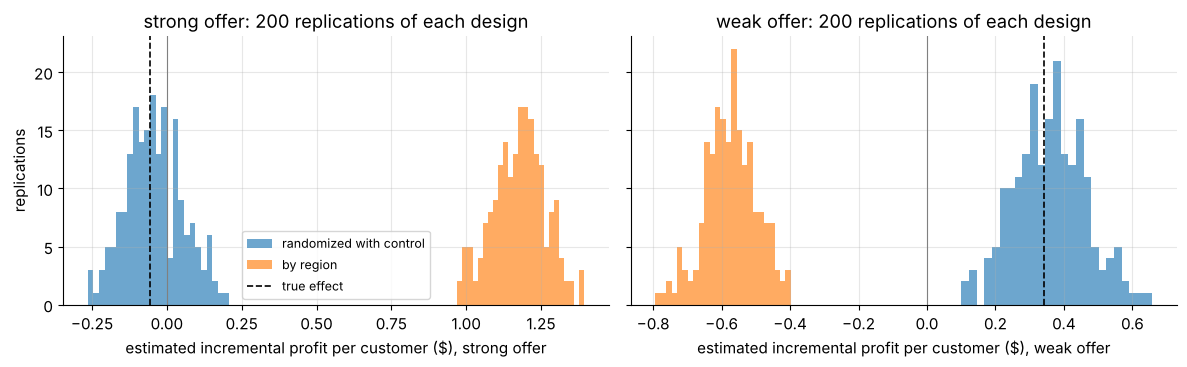

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, arm in [(axes[0], "incr_profit_strong", "strong"), (axes[1], "incr_profit_weak", "weak")]:
    for design in ["randomized with control", "by region"]:
        ax.hist(mc.loc[mc["design"] == design, col], bins=25, alpha=0.65, label=design)
    ax.axvline(truth.loc[arm, "incremental_profit"], color="k", ls="--", lw=1.2, label="true effect")
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlabel(f"estimated incremental profit per customer ($), {arm} offer")
    ax.set_title(f"{arm} offer: 200 replications of each design")
axes[0].set_ylabel("replications")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

* **Randomized with control** is unbiased: averaged over replications it reproduces the true uplifts
  and incremental profits, and it launches the weak offer in all 200 replications.
* **Randomized, no control** cannot measure uplift or incremental profit at all (those columns are
  `NaN`: there is nothing to subtract). Ranked by response rate, the strong offer wins every time,
  which is the wrong launch. Ranking by profit per customer would order the two offers correctly, but
  it still could not say whether *either* offer beats sending nothing.
* **By region** is confounded. North customers buy more and spend more *regardless of the offer*,
  so the strong offer (run in the North) looks hugely profitable, while the weak offer (run in the
  South, the weakest region) looks like it destroys value. The selection-bias term of §5.1 is now
  larger than the effects themselves, and the design launches the wrong offer in every replication.
  The histograms make the difference visible: the randomized estimates scatter *around* the true
  effects, while the by-region estimates are tightly clustered around the wrong values. More data
  would only make a biased design more confidently wrong.

> **Key idea.** Randomization is what turns a difference between groups into an estimate of a
> causal effect. A control group is what turns "the offer group did well" into "the offer *caused*
> this much extra profit, after paying for itself".

### 5.5 How sure are we? Bootstrap confidence intervals

One experiment gives one estimate. The **bootstrap** approximates its sampling variability using
only the data we have: resample the customers of each arm *with replacement* (same arm sizes),
recompute the estimate, repeat many times, and read off the 2.5th and 97.5th percentiles. Resampling
within arms mirrors how the data were generated (arm sizes were fixed by design).

For a difference of two means there is also a normal approximation,
$\hat\Delta \pm 1.96\sqrt{s_t^2/n_t + s_c^2/n_c}$ with sample standard deviations $s_t$, $s_c$. Profit
per customer is very skewed (most customers spend \$0, a few spend a lot), which is exactly when it is
reassuring to see the bootstrap agree.

incremental profit per customer ($), 95% intervals from the single experiment:
                  estimate  bootstrap 2.5%  bootstrap 97.5%  normal 2.5%  normal 97.5%
strong - control    -0.081          -0.249            0.096       -0.259         0.097
weak - control       0.376           0.185            0.565        0.180         0.571
weak - strong        0.457           0.276            0.631        0.276         0.638


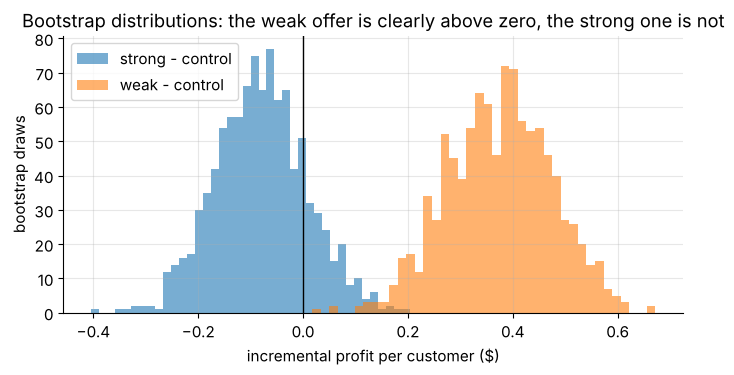

In [46]:
def bootstrap_incremental_profit(arm, profit, B=1000, seed=0):
    """Bootstrap draws of incremental profit per customer (strong, weak) and of weak minus strong."""
    rng = np.random.default_rng(seed)
    groups = [profit[arm == a] for a in range(3)]
    draws = np.empty((B, 3))
    for b in range(B):
        means = [g[rng.integers(0, len(g), len(g))].mean() for g in groups]
        draws[b] = [means[1] - means[0], means[2] - means[0], means[2] - means[1]]
    return draws


boot = bootstrap_incremental_profit(arm_rct, profit_rct)
labels_ci = ["strong - control", "weak - control", "weak - strong"]
point = [profit_rct[arm_rct == 1].mean() - profit_rct[arm_rct == 0].mean(),
         profit_rct[arm_rct == 2].mean() - profit_rct[arm_rct == 0].mean(),
         profit_rct[arm_rct == 2].mean() - profit_rct[arm_rct == 1].mean()]
pairs_ci = [(1, 0), (2, 0), (2, 1)]
se = [np.sqrt(profit_rct[arm_rct == t].var(ddof=1) / np.sum(arm_rct == t) +
              profit_rct[arm_rct == c].var(ddof=1) / np.sum(arm_rct == c)) for t, c in pairs_ci]
ci_table = pd.DataFrame({"estimate": point,
                         "bootstrap 2.5%": np.quantile(boot, 0.025, axis=0),
                         "bootstrap 97.5%": np.quantile(boot, 0.975, axis=0),
                         "normal 2.5%": np.array(point) - 1.96 * np.array(se),
                         "normal 97.5%": np.array(point) + 1.96 * np.array(se)}, index=labels_ci)
print("incremental profit per customer ($), 95% intervals from the single experiment:")
print(ci_table.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
for j, lab in enumerate(labels_ci[:2]):
    ax.hist(boot[:, j], bins=40, alpha=0.6, label=lab)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("incremental profit per customer ($)")
ax.set_ylabel("bootstrap draws")
ax.set_title("Bootstrap distributions: the weak offer is clearly above zero, the strong one is not")
ax.legend()
plt.show()

Both methods agree here (30,000 customers per arm is plenty for the averages to be nearly normal).
The weak offer's interval is well above zero, the strong offer's interval straddles zero, and the
weak-minus-strong interval excludes zero, so the launch decision is supported by the data, not just
by the point estimates.

> **Quick check.** Why do we resample customers *within each arm* instead of pooling all 90,000
> customers and resampling them together?

<details>
<summary>Answer</summary>

The bootstrap should imitate how the data were produced. In the experiment each arm had a fixed
size (30,000) and its own outcome distribution. Resampling within arms keeps both. Pooling would
mix treated and untreated customers, so every bootstrap "arm" would contain a different random
number of each, which is not a source of variability the real experiment had.
</details>

### 5.6 How many customers do you need?

The standard error of a difference between two arm means with $n$ customers each is
$\sqrt{(\sigma_t^2 + \sigma_c^2)/n}$. To detect a true difference $\Delta$ with a two-sided test at
level $\alpha = 0.05$ and **power** $1-\beta = 0.8$ (an 80% chance of a significant result when the
effect is real), the classic approximation is

$$
n_{\text{per arm}} \approx \frac{(z_{1-\alpha/2} + z_{1-\beta})^2\,(\sigma_t^2 + \sigma_c^2)}{\Delta^2}
\approx \frac{7.85 \times 2\sigma^2}{\Delta^2} \quad (\sigma_t \approx \sigma_c = \sigma).
$$

Two lessons hide in this formula: $n$ grows with the **square** of $1/\Delta$ (halving the effect you
want to detect quadruples the sample), and **noisy outcomes** need far more data. A purchase
indicator has $\sigma^2 = p(1-p) \approx 0.06$. Profit per customer, which is mostly zeros with a
few large values, has a much larger variance relative to the effect.

In [47]:
from scipy.stats import norm

z_sum_sq = (norm.ppf(0.975) + norm.ppf(0.80)) ** 2
p_ctrl = buy_rct[arm_rct == 0].mean()
sd_profit = profit_rct[arm_rct == 0].std(ddof=1)
needs = pd.DataFrame({
    "outcome": ["purchase (yes/no)", "profit per customer ($)"],
    "sigma": [np.sqrt(p_ctrl * (1 - p_ctrl)), sd_profit],
    "effect to detect": [0.02, 0.34],
})
needs["n per arm"] = np.ceil(z_sum_sq * 2 * needs["sigma"] ** 2 / needs["effect to detect"] ** 2).astype(int)
print(f"(z_0.975 + z_0.80)^2 = {z_sum_sq:.2f}")
print(needs.round(3).to_string(index=False))

# What if we ran the test only on our own store's light buyers (about 2,000 customers, ~670 per arm)?
small_rng = np.random.default_rng(3)
hits = []
for rep in range(300):
    idx = small_rng.choice(N_EXP, size=2016, replace=False)
    arm_s = small_rng.permutation(np.arange(idx.size) % 3)
    _, prof_s = simulate_outcomes(arm_s, p0[idx], value[idx], small_rng)
    d = prof_s[arm_s == 2].mean() - prof_s[arm_s == 0].mean()
    se_s = np.sqrt(prof_s[arm_s == 2].var(ddof=1) / np.sum(arm_s == 2) + prof_s[arm_s == 0].var(ddof=1) / np.sum(arm_s == 0))
    hits.append(d - 1.96 * se_s > 0)
print(f"\nwith ~670 customers per arm, the weak offer's profit effect is detected in {np.mean(hits):.0%} of experiments")

(z_0.975 + z_0.80)^2 = 7.85
                outcome  sigma  effect to detect  n per arm
      purchase (yes/no)  0.243              0.02       2321
profit per customer ($) 12.040              0.34      19685



with ~670 customers per arm, the weak offer's profit effect is detected in 9% of experiments


Detecting a 2-point uplift in the purchase rate needs about 2,300 customers per arm, but detecting
the weak offer's \$0.34 profit effect needs almost 20,000 per arm, because profit per customer has a
standard deviation of about \$12. Our simulated test (30,000 per arm) was big enough. Run on our own
store's 2,000 light buyers, the same experiment would detect the effect only about 9% of the time and
would usually end "inconclusive": not because the offer fails, but because the test is too small. Plan the
sample size **before** the experiment, for the outcome you will actually decide on (profit, not
clicks).

> **Going deeper.** Real campaign tests add refinements we skipped: pre-registering the primary
> metric, a holdout that stays untreated for longer to measure lasting effects, CUPED-style variance
> reduction with pre-period spend, and *uplift modeling*, which estimates the effect per customer so
> the offer can be targeted to those it actually changes.

### ✏️ Exercise 8: campaign economics from an arm summary

Write `campaign_economics(arms, margin)` that takes a table with one row per arm (columns
`customers`, `buyers`, `list_revenue` (total list value of purchases), `discount`, `contact_cost`.
The control row is named `"control"`) and returns a copy with three new columns: `uplift_pp`
(response-rate difference vs control, in percentage points), `profit_per_customer`
(`((margin - discount) * list_revenue - contact_cost * customers) / customers`: the margin left
after the discount, earned on the list revenue, minus the contact costs, per customer) and
`incremental_profit` (profit per customer minus the control's).

In [48]:
# ✏️ Exercise 8: uplift and incremental profit
def campaign_economics(arms: pd.DataFrame, margin: float) -> pd.DataFrame:
    """Add uplift_pp, profit_per_customer and incremental_profit columns (vs the 'control' row)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex8():
    arms = pd.DataFrame({"customers": [10_000, 10_000, 10_000], "buyers": [500, 700, 620],
                         "list_revenue": [40_000.0, 56_000.0, 49_600.0], "discount": [0.0, 0.20, 0.05],
                         "contact_cost": [0.0, 0.10, 0.10]}, index=["control", "offer A", "offer B"])
    out = campaign_economics(arms, margin=0.5)
    assert np.allclose(out["uplift_pp"], [0.0, 2.0, 1.2]), f"uplift_pp: {out['uplift_pp'].tolist()}"
    assert np.allclose(out["profit_per_customer"], [2.0, 1.58, 2.132]), f"profit: {out['profit_per_customer'].tolist()}"
    assert np.allclose(out["incremental_profit"], [0.0, -0.42, 0.132]), f"incremental: {out['incremental_profit'].tolist()}"
    assert "uplift_pp" not in arms.columns, "do not modify the input table in place"


run_check("Exercise 8", _test_ex8)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def campaign_economics(arms, margin):
    out = arms.copy()
    rate = out["buyers"] / out["customers"]
    out["uplift_pp"] = 100 * (rate - rate["control"])
    profit = (margin - out["discount"]) * out["list_revenue"] - out["contact_cost"] * out["customers"]
    out["profit_per_customer"] = profit / out["customers"]
    out["incremental_profit"] = out["profit_per_customer"] - out.loc["control", "profit_per_customer"]
    return out
```
Offer A: response 7% vs 5% (+2.0 points), profit $(0.5-0.2)\times 56{,}000 - 0.10\times 10{,}000 = 15{,}800$,
i.e. \$1.58 per customer, \$0.42 *less* than doing nothing. Offer B: $0.45 \times 49{,}600 - 1{,}000 = 21{,}320$,
\$2.132 per customer, \$0.132 more than control. Bigger uplift, smaller profit: the same lesson as §5.2.
</details>

### ✏️ Exercise 9: sample size per arm

Write `n_per_arm(sigma, delta, alpha=0.05, power=0.8)` returning the smallest integer
$n \ge \frac{(z_{1-\alpha/2} + z_{\text{power}})^2 \cdot 2\sigma^2}{\Delta^2}$ (use `norm.ppf`).

In [49]:
# ✏️ Exercise 9: sample size
def n_per_arm(sigma: float, delta: float, alpha: float = 0.05, power: float = 0.8) -> int:
    """Customers needed in EACH arm to detect a mean difference delta (two-sided test, equal sigmas)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex9():
    assert n_per_arm(1.0, 0.1) == 1570, f"sigma=1, delta=0.1: got {n_per_arm(1.0, 0.1)}"
    assert n_per_arm(1.0, 0.05) == 6280, "halving delta should multiply n by about 4"
    assert n_per_arm(2.0, 0.1) == 6280, "doubling sigma should multiply n by about 4"
    assert n_per_arm(1.0, 0.1, power=0.9) == 2102, "more power needs more customers"


run_check("Exercise 9", _test_ex9)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def n_per_arm(sigma, delta, alpha=0.05, power=0.8):
    z = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    return int(np.ceil(z ** 2 * 2 * sigma ** 2 / delta ** 2))
```
With $\sigma = 1$ and $\Delta = 0.1$: $7.849 \times 2 / 0.01 = 1569.8$, so 1,570 per arm.
</details>

---
## 6. Vector search: from exact k-NN to IVF and HNSW

Modern AI systems represent products, documents and images as **embedding vectors**, and "find
similar items" becomes "find the nearest vectors". With a database $X_b \in \mathbb{R}^{N\times d}$
and a query $\mathbf{q} \in \mathbb{R}^d$, the exact $k$ nearest neighbors are the $k$ rows with the
smallest $\lVert \mathbf{x} - \mathbf{q} \rVert^2$.

### 6.1 Exact search and how we score approximate search

Exact (brute-force) search computes all $N$ distances: $O(Nd)$ work per query. For $N$ = 40,000 and
$d$ = 48 that is about two million multiply-adds per query, which is fine. For a billion vectors
and thousands of queries per second it is not. **Approximate nearest-neighbor (ANN)** indexes
trade a little accuracy for a lot of speed by scanning only a small, well-chosen part of the
database.

Accuracy is measured against exact search:

$$
\text{Recall@}k = \frac{1}{|Q|}\sum_{\mathbf{q}\in Q} \frac{|\,\text{ANN}_k(\mathbf{q}) \cap \text{exact}_k(\mathbf{q})\,|}{k} ,
$$

the average fraction of the true top-$k$ that the index returns. Example: true top-5 = {3, 8, 12, 20, 41},
returned = {3, 8, 12, 19, 41}: recall $4/5 = 0.8$ for that query.

Our data: synthetic "embedding-like" vectors in $d = 48$ dimensions, generated around topics (as
real embeddings cluster around themes), with some directions carrying more variance than others,
and randomly rotated so that no coordinate axis is special. We make **two** datasets:

* a **benchmark** set (60 tight topics), standing in for a public benchmark you might tune on.
* a **target** set (30 broader, more overlapping topics), standing in for *your* catalog.

In [50]:
def make_vectors(n, d=48, n_topics=60, spread=1.0, decay=0.6, seed=0) -> np.ndarray:
    """Clustered embedding-like vectors: Gaussian topics, decaying spectrum, random rotation (float32)."""
    rng = np.random.default_rng(seed)
    spec = (1.0 / np.arange(1, d + 1)) ** decay              # some directions carry more variance
    spec /= np.sqrt(np.mean(spec ** 2))
    centers = rng.normal(size=(n_topics, d)) * spec * 2.0
    topic = rng.integers(0, n_topics, n)
    width = rng.uniform(0.7, 1.3, n_topics)[topic, None] * spread
    Q, _ = np.linalg.qr(rng.normal(size=(d, d)))              # random orthogonal rotation
    X = (centers[topic] + rng.normal(size=(n, d)) * spec * width) @ Q.T
    return X.astype(np.float32)


def exact_knn(xb, xq, k, chunk=100):
    """Exact k nearest neighbors (indices sorted by distance), computed in float64 for reliable ties."""
    xb64 = xb.astype(np.float64)
    nb = (xb64 ** 2).sum(axis=1)
    out = []
    for s in range(0, len(xq), chunk):
        q = xq[s:s + chunk].astype(np.float64)
        d2 = (q ** 2).sum(axis=1)[:, None] - 2.0 * q @ xb64.T + nb[None, :]
        idx = np.argpartition(d2, k, axis=1)[:, :k]                 # unordered top-k in O(N)
        order = np.take_along_axis(d2, idx, axis=1).argsort(axis=1)
        out.append(np.take_along_axis(idx, order, axis=1))
    return np.vstack(out)


def recall_at_k(I_approx, I_exact) -> float:
    """Mean fraction of each query's exact top-k found in the approximate top-k."""
    k = I_exact.shape[1]
    return float(np.mean([len(set(a) & set(b)) / k for a, b in zip(I_approx, I_exact)]))


N_DB, N_Q, K_NN = 40_000, 400, 20
X_bench = make_vectors(N_DB + N_Q, n_topics=60, spread=1.0, decay=0.6, seed=0)
X_target = make_vectors(N_DB + N_Q, n_topics=30, spread=1.6, decay=0.3, seed=1)
xb, xq = X_bench[:N_DB], X_bench[N_DB:]                  # database and held-out queries
xb_t, xq_t = X_target[:N_DB], X_target[N_DB:]

t0 = time.perf_counter()
I_true = exact_knn(xb, xq, K_NN)
t_exact = (time.perf_counter() - t0) / N_Q * 1e3
I_true_t = exact_knn(xb_t, xq_t, K_NN)
print(f"database {xb.shape}, queries {xq.shape}; NumPy exact search: {t_exact:.2f} ms per query")
print(f"recall of exact search against itself: {recall_at_k(I_true, I_true):.3f}")

database (40000, 48), queries (400, 48); NumPy exact search: 0.92 ms per query
recall of exact search against itself: 1.000


### 6.2 IVF-Flat from scratch: search only the most promising clusters

The **inverted file (IVF)** idea is K-means put to work:

1. **Train** a *coarse quantizer*: run K-means with `nlist` centroids on (a sample of) the database.
2. **Add**: store every database vector in the *inverted list* of its nearest centroid. ("Flat"
   means the vectors are stored as they are, uncompressed.)
3. **Search** with parameter `nprobe`: compute the query's distance to the `nlist` centroids, open
   the `nprobe` closest lists, and compute exact distances only to the vectors in those lists.

With `nlist` = 256 lists of about 156 vectors each, `nprobe` = 8 scans about $8 \times 156 \approx 1{,}250$
vectors plus 256 centroid distances instead of 40,000 vectors. The price: a true neighbor stored in a
list that was not opened is missed. This happens for queries near the *boundary* between cells, which
is why recall rises with `nprobe`.

```text
  query q ──► distances to 256 centroids ──► open the nprobe nearest lists
                                                  │
       list 17: [ids ...]   list 203: [ids ...]   list 88: [ids ...]  ...
                                                  │
                          exact distances to those candidates only ──► top-k
```

In [51]:
class IVFFlatScratch:
    """A minimal IVF-Flat index: K-means coarse quantizer + inverted lists + exact scan of probed lists."""

    def __init__(self, nlist: int, seed: int = 0):
        self.nlist, self.seed = nlist, seed

    def train(self, sample: np.ndarray):
        km = KMeans(n_clusters=self.nlist, n_init=1, max_iter=25, random_state=self.seed).fit(sample)
        self.centroids = km.cluster_centers_.astype(np.float32)
        return self

    def add(self, xb: np.ndarray):
        self.xb = xb
        assign = sq_dists(xb, self.centroids).argmin(axis=1)
        self.ids = np.argsort(assign, kind="stable")                     # vector ids grouped by list
        self.offsets = np.searchsorted(assign[self.ids], np.arange(self.nlist + 1))
        return self

    def search(self, xq: np.ndarray, k: int, nprobe: int):
        """Return (I, n_scanned): top-k ids per query and the number of vectors scanned per query."""
        I = np.full((len(xq), k), -1, dtype=np.int64)        # -1 = "no result", as in FAISS
        scanned = np.empty(len(xq), dtype=np.int64)
        dc = sq_dists(xq, self.centroids)
        for i, q in enumerate(xq):
            probe = np.argpartition(dc[i], nprobe - 1)[:nprobe]
            cand = np.concatenate([self.ids[self.offsets[c]:self.offsets[c + 1]] for c in probe])
            d2 = ((self.xb[cand] - q) ** 2).sum(axis=1)
            top = np.argsort(d2)[:k]
            I[i, :len(top)] = cand[top]
            scanned[i] = cand.size
        return I, scanned


t0 = time.perf_counter()
ivf_s = IVFFlatScratch(nlist=256).train(xb[np.random.default_rng(0).choice(N_DB, 10_000, replace=False)]).add(xb)
print(f"trained + filled in {time.perf_counter() - t0:.1f} s; list sizes: min {np.diff(ivf_s.offsets).min()}, "
      f"median {np.median(np.diff(ivf_s.offsets)):.0f}, max {np.diff(ivf_s.offsets).max()}")
rows = []
for nprobe in (1, 2, 4, 8, 16, 32):
    I_s, scanned = ivf_s.search(xq, K_NN, nprobe)
    rows.append({"nprobe": nprobe, "recall@20": recall_at_k(I_s, I_true),
                 "vectors scanned": scanned.mean(), "fraction of database": scanned.mean() / N_DB})
scratch_tab = pd.DataFrame(rows)
print(scratch_tab.round(4).to_string(index=False))

trained + filled in 0.8 s; list sizes: min 18, median 140, max 684


 nprobe  recall@20  vectors scanned  fraction of database
      1     0.7151         191.0050                0.0048
      2     0.9150         372.9550                0.0093
      4     0.9965         661.6075                0.0165
      8     1.0000        1270.2775                0.0318
     16     1.0000        2514.0725                0.0629
     32     1.0000        5050.6700                0.1263


Two things to notice. Recall climbs quickly: with `nprobe` = 4 we already find nearly all true
neighbors while scanning under 2% of the database. And one probe scans more vectors (about 190) than
the median list holds (140): K-means cells are unbalanced, and queries, which come from the same
distribution as the data, tend to fall into the big, dense cells.

**Why does a query miss neighbors?** The same mechanism is easiest to see in two dimensions. Below,
2,000 points are split into 16 IVF cells, and the query is a point that lies almost exactly on the
boundary between two cells.

nprobe = 1: 5 of the 15 true neighbors found
nprobe = 2: 15 of the 15 true neighbors found


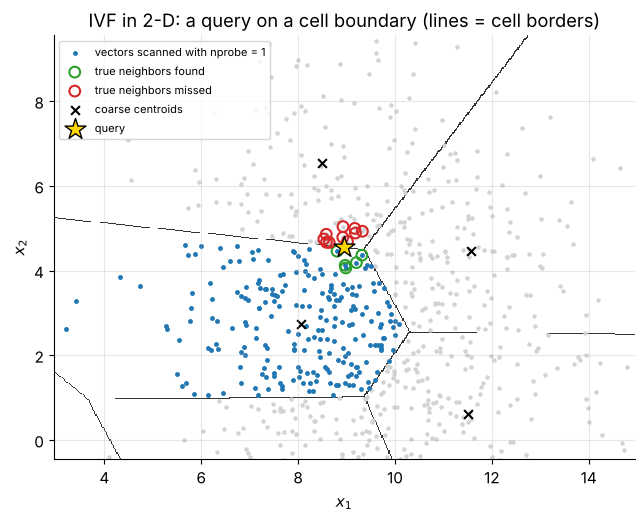

In [52]:
pts2d, _ = make_blobs(n_samples=2000, centers=5, cluster_std=2.2, random_state=4)
coarse2d = KMeans(n_clusters=16, n_init=1, random_state=0).fit(pts2d)
cent2d = coarse2d.cluster_centers_
gap = np.diff(np.sort(sq_dists(pts2d, cent2d), axis=1)[:, :2], axis=1).ravel()   # 2nd minus 1st nearest
density = (sq_dists(pts2d, pts2d) < 1.0).sum(axis=1)                              # neighbors within radius 1
qi = int(np.argmin(np.where(density > np.median(density), gap, np.inf)))          # boundary point, dense area
q2d = pts2d[qi]
db2d, cell2d = np.delete(pts2d, qi, axis=0), np.delete(coarse2d.labels_, qi)
true15 = np.argsort(((db2d - q2d) ** 2).sum(axis=1))[:15]
cell_order = np.argsort(((cent2d - q2d) ** 2).sum(axis=1))                         # cells by distance to q
for nprobe in (1, 2):
    print(f"nprobe = {nprobe}: {np.isin(cell2d[true15], cell_order[:nprobe]).sum()} of the 15 true neighbors found")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
x_lo, x_hi, y_lo, y_hi = q2d[0] - 6, q2d[0] + 6, q2d[1] - 5, q2d[1] + 5
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 500), np.linspace(y_lo, y_hi, 500))
grid_cell = sq_dists(np.c_[gx.ravel(), gy.ravel()], cent2d).argmin(axis=1).reshape(gx.shape)
edge = np.zeros(grid_cell.shape, dtype=bool)                     # pixels where the cell id changes
edge[:-1, :] |= grid_cell[:-1, :] != grid_cell[1:, :]
edge[:, :-1] |= grid_cell[:, :-1] != grid_cell[:, 1:]
ax.imshow(np.where(edge, 1.0, np.nan), extent=(x_lo, x_hi, y_lo, y_hi), origin="lower",
          cmap="Greys", vmin=0, vmax=1.2, interpolation="nearest", aspect="auto")
ax.scatter(db2d[:, 0], db2d[:, 1], s=5, c="lightgray")
scanned = cell2d == cell_order[0]
ax.scatter(db2d[scanned, 0], db2d[scanned, 1], s=6, c="C0", label="vectors scanned with nprobe = 1")
missed = ~np.isin(cell2d[true15], cell_order[:1])
ax.scatter(db2d[true15[~missed], 0], db2d[true15[~missed], 1], s=60, facecolors="none",
           edgecolors="C2", linewidths=1.5, label="true neighbors found")
ax.scatter(db2d[true15[missed], 0], db2d[true15[missed], 1], s=60, facecolors="none",
           edgecolors="C3", linewidths=1.5, label="true neighbors missed")
ax.scatter(cent2d[:, 0], cent2d[:, 1], marker="x", c="k", s=40, label="coarse centroids")
ax.scatter(*q2d, marker="*", s=250, c="gold", edgecolors="k", label="query", zorder=5)
ax.set_xlim(x_lo, x_hi)
ax.set_ylim(y_lo, y_hi)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("IVF in 2-D: a query on a cell boundary (lines = cell borders)")
ax.legend(fontsize=8, loc="upper left")
plt.show()

With `nprobe` = 1 the index scans only the query's own cell (blue) and finds just 5 of the 15
true neighbors. The other 10 sit a short distance away, but across the border. Opening the
second-nearest cell (`nprobe` = 2) recovers all of them. In 48 dimensions a query has many more
neighboring cells, which is why the recall curve above needs a few probes to saturate.

> **Quick check.** You rebuild the 40,000-vector IVF index with `nlist` = 512 instead of 256 and keep
> `nprobe` = 8. Roughly what happens to the number of vectors scanned per query, and to recall?

<details>
<summary>Answer</summary>

Lists become about half as long (about 78 instead of 156 vectors), so a query scans roughly half
as many vectors (plus 512 instead of 256 centroid distances). But each probed cell now covers a
smaller region, so more true neighbors fall outside the 8 opened cells and recall drops. To keep
the same recall you would need roughly twice the probes, and the saving largely disappears. `nlist`
and `nprobe` must be tuned together (a common starting point is `nlist` between $\sqrt{N}$ and a
few times $\sqrt{N}$, then a sweep over `nprobe`).
</details>

### 6.3 The same ideas in FAISS: Flat, IVF-Flat and HNSW

FAISS (an open-source library from Meta AI) implements these indexes in optimized C++ with a Python
interface. All indexes share one API: `index.add(xb)` to insert vectors, `index.search(xq, k)` to get
distances `D` and ids `I` (both of shape `(n_queries, k)`), and `index.train(x)` for indexes that must
learn something first (IVF learns its coarse centroids). FAISS works with `float32` arrays.

* **`IndexFlatL2`**: exact brute-force search, the ground truth.
* **`IndexIVFFlat`**: exactly our §6.2 index, and the knob is `nprobe`.
* **`IndexHNSWFlat`**: a *Hierarchical Navigable Small World* graph. Every vector is a node linked
  to a few dozen near neighbors (at most `M` per layer, or `2M` on the bottom layer in FAISS), and
  the neighbor-selection rule keeps links that point in diverse directions. Each vector also appears
  in upper layers with exponentially decreasing probability, so the upper layers are sparse and act
  like an express highway. A search starts at the top layer, walks greedily toward the query, drops
  a layer, and repeats. On the bottom layer it keeps a candidate list of size `efSearch` (a beam)
  and expands the most promising candidates until none can improve the list. Larger `efSearch` means
  more nodes visited: higher recall, more time. `efConstruction` plays the same role while building.

We pin FAISS to one thread so that latency numbers measure the algorithm rather than how many cores
happen to be free. Each timing is the best of seven runs over the 400 queries (after one untimed
warm-up search), reported per query.

In [53]:
faiss = ensure("faiss-cpu", "faiss")
faiss.omp_set_num_threads(1)
print("faiss version:", faiss.__version__)


def timed_search(index, xq, k, reps=7):
    """Warm up, run index.search reps times, and return the ids and the best time in milliseconds per query."""
    index.search(xq[:20], k)                                   # warm-up call, not timed
    best = np.inf
    for _ in range(reps):
        t = time.perf_counter()
        _, I = index.search(xq, k)
        best = min(best, time.perf_counter() - t)
    return I, best / len(xq) * 1e3


def build_indexes(xb, nlist=256, M=16, ef_construction=40):
    d = xb.shape[1]
    flat = faiss.IndexFlatL2(d)
    flat.add(xb)
    ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(d), d, nlist)     # the inner IndexFlatL2 holds the centroids
    ivf.train(xb)
    ivf.add(xb)
    hnsw = faiss.IndexHNSWFlat(d, M)
    hnsw.hnsw.efConstruction = ef_construction
    hnsw.add(xb)
    return flat, ivf, hnsw


t0 = time.perf_counter()
flat, ivf, hnsw = build_indexes(xb)
print(f"built Flat + IVF-Flat + HNSW on the benchmark set in {time.perf_counter() - t0:.1f} s")
I_flat, ms_flat = timed_search(flat, xq, K_NN)
print(f"IndexFlatL2: recall@20 vs our NumPy ground truth = {recall_at_k(I_flat, I_true):.4f}, {ms_flat:.3f} ms/query")


def sweep(index, param, values, xq, I_true, k=K_NN):
    """Recall@k and latency for each value of nprobe (IVF) or efSearch (HNSW)."""
    rows = []
    for v in values:
        if param == "nprobe":
            index.nprobe = v
        else:
            index.hnsw.efSearch = v
        I, ms = timed_search(index, xq, k)
        rows.append({param: v, "recall@20": recall_at_k(I, I_true), "ms/query": ms})
    return pd.DataFrame(rows)


NPROBE_GRID = [1, 2, 4, 8, 16, 32, 64]
EF_GRID = [20, 32, 48, 64, 96, 128, 256]
ivf_bench = sweep(ivf, "nprobe", NPROBE_GRID, xq, I_true)
hnsw_bench = sweep(hnsw, "efSearch", EF_GRID, xq, I_true)
print("\nIVF-Flat on the benchmark set:")
print(ivf_bench.round(4).to_string(index=False))
print("\nHNSW on the benchmark set:")
print(hnsw_bench.round(4).to_string(index=False))

faiss version: 1.15.1


built Flat + IVF-Flat + HNSW on the benchmark set in 2.5 s


IndexFlatL2: recall@20 vs our NumPy ground truth = 1.0000, 0.492 ms/query



IVF-Flat on the benchmark set:
 nprobe  recall@20  ms/query
      1     0.7191    0.0066
      2     0.9215    0.0092
      4     0.9960    0.0122
      8     1.0000    0.0173
     16     1.0000    0.0390
     32     1.0000    0.0729
     64     1.0000    0.1468

HNSW on the benchmark set:
 efSearch  recall@20  ms/query
       20     0.9559    0.0124
       32     0.9810    0.0180
       48     0.9924    0.0334
       64     0.9932    0.0419
       96     0.9935    0.0622
      128     0.9959    0.0717
      256     0.9988    0.1324


`IndexFlatL2` agrees perfectly with our NumPy ground truth: it computes the same distances, with
optimized single-precision matrix kernels. The IVF numbers closely track our from-scratch index.
FAISS trains its own coarse quantizer, so the values differ slightly.

Trust the recall columns more than the latency columns. Recall is deterministic, but wall-clock
timings this small (hundredths of a millisecond per query) are noisy, especially on a busy machine
where other programs compete for the CPU. Neighboring grid points can then come out in the wrong
order. That is most likely when the settings are close together, as in the refined `efSearch` grid
of the next cell, but on a busy machine it can happen even in the coarse tables above and in the
recall–latency plot below. The *work* per query still grows with `nprobe` and `efSearch`. For IVF,
the vectors-scanned counts of our §6.2 index measure it without any noise.

### 6.4 Choosing the operating point

Every ANN index has a knob that trades recall for latency. A defensible way to set it:

1. **Fix the requirement first**: here, Recall@20 $\ge 0.97$ on held-out queries, measured single-threaded.
2. **Sweep a coarse grid** (powers of two are a good start) and find the **smallest** setting that
   meets the target. Latency grows with `nprobe` and `efSearch`, so the smallest passing value is
   the cheapest acceptable one.
3. **Refine** between the last failing and the first passing grid value: the coarse grid can
   overshoot by almost a factor of two.
4. **Re-validate on the target data and hardware.** A setting tuned on a benchmark is a hypothesis,
   not a guarantee: recall depends on how the data cluster, and latency on the machine.

In [54]:
TARGET = 0.97


def smallest_passing(table: pd.DataFrame, param: str, target: float = TARGET):
    """Smallest parameter value whose recall meets the target (None if none does)."""
    ok = table[table["recall@20"] >= target]
    return None if ok.empty else int(ok[param].min())


def refine(index, param, coarse, xq, I_true, target=TARGET):
    """Sweep a finer grid between the last failing and the first passing coarse value."""
    hi = smallest_passing(coarse, param, target)
    if hi is None:
        raise ValueError(f"no {param} value in the coarse grid reaches recall {target}")
    below = coarse.loc[coarse[param] < hi, param]
    lo = int(below.max()) if len(below) else hi
    if hi - lo <= 8:
        values = list(range(lo + 1, hi))
    else:
        values = [int(v) for v in np.unique(np.linspace(lo, hi, 9).astype(int))[1:-1]]
    fine = sweep(index, param, values, xq, I_true) if values else coarse.iloc[:0]
    merged = pd.concat([coarse, fine]).sort_values(param).drop_duplicates(param)
    return smallest_passing(merged, param, target), fine


choice = {}
for name, index, param, coarse in [("IVF", ivf, "nprobe", ivf_bench), ("HNSW", hnsw, "efSearch", hnsw_bench)]:
    first = smallest_passing(coarse, param)
    best, fine = refine(index, param, coarse, xq, I_true)
    choice[name] = best
    print(f"{name}: coarse grid -> {param} = {first}; refined grid:")
    print("   " + fine.round(4).to_string(index=False).replace("\n", "\n   "))
    print(f"   -> chosen {param} = {best}")

IVF: coarse grid -> nprobe = 4; refined grid:
    nprobe  recall@20  ms/query
         3     0.9841     0.011
   -> chosen nprobe = 3


HNSW: coarse grid -> efSearch = 32; refined grid:
    efSearch  recall@20  ms/query
          21     0.9614    0.0150
          23     0.9669    0.0138
          24     0.9685    0.0143
          26     0.9716    0.0236
          27     0.9734    0.0160
          29     0.9752    0.0215
          30     0.9760    0.0170
   -> chosen efSearch = 26


Now the reality check. We build the same indexes on the **target** set (our "catalog") and test the
settings chosen on the benchmark.

In [55]:
t0 = time.perf_counter()
flat_t, ivf_t, hnsw_t = build_indexes(xb_t)
print(f"built indexes on the target set in {time.perf_counter() - t0:.1f} s")
check = []
for name, index, param in [("IVF", ivf_t, "nprobe"), ("HNSW", hnsw_t, "efSearch")]:
    res = sweep(index, param, [choice[name]], xq_t, I_true_t).iloc[0]
    check.append({"index": name, "setting tuned on benchmark": f"{param} = {choice[name]}",
                  "recall@20 on target": res["recall@20"], "meets 0.97?": res["recall@20"] >= TARGET})
print(pd.DataFrame(check).round(4).to_string(index=False))

ivf_target = sweep(ivf_t, "nprobe", NPROBE_GRID, xq_t, I_true_t)
hnsw_target = sweep(hnsw_t, "efSearch", EF_GRID, xq_t, I_true_t)
choice_t = {}
for name, index, param, coarse in [("IVF", ivf_t, "nprobe", ivf_target), ("HNSW", hnsw_t, "efSearch", hnsw_target)]:
    choice_t[name], _ = refine(index, param, coarse, xq_t, I_true_t)
print(f"\nre-tuned on the target set: IVF nprobe = {choice_t['IVF']} (benchmark said {choice['IVF']}), "
      f"HNSW efSearch = {choice_t['HNSW']} (benchmark said {choice['HNSW']})")

built indexes on the target set in 3.2 s


index setting tuned on benchmark  recall@20 on target  meets 0.97?
  IVF                 nprobe = 3               0.7803        False
 HNSW              efSearch = 26               0.9045        False



re-tuned on the target set: IVF nprobe = 7 (benchmark said 3), HNSW efSearch = 58 (benchmark said 26)


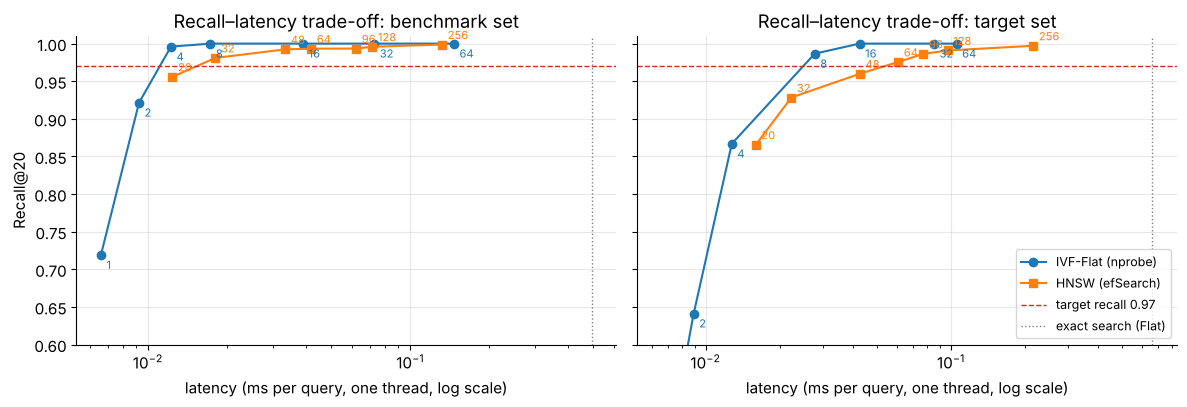

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (title, ivf_tab, hnsw_tab, ms_ref) in zip(axes, [
        ("benchmark set", ivf_bench, hnsw_bench, ms_flat),
        ("target set", ivf_target, hnsw_target, timed_search(flat_t, xq_t, K_NN)[1])]):
    ax.plot(ivf_tab["ms/query"], ivf_tab["recall@20"], "o-", label="IVF-Flat (nprobe)")
    for _, r in ivf_tab.iterrows():
        ax.annotate(int(r["nprobe"]), (r["ms/query"], r["recall@20"]), textcoords="offset points",
                    xytext=(4, -10), fontsize=8, color="C0")
    ax.plot(hnsw_tab["ms/query"], hnsw_tab["recall@20"], "s-", label="HNSW (efSearch)")
    for _, r in hnsw_tab.iterrows():
        ax.annotate(int(r["efSearch"]), (r["ms/query"], r["recall@20"]), textcoords="offset points",
                    xytext=(4, 4), fontsize=8, color="C1")
    ax.axhline(TARGET, color="C3", ls="--", lw=1, label=f"target recall {TARGET}")
    ax.axvline(ms_ref, color="gray", ls=":", lw=1, label="exact search (Flat)")
    ax.set_xscale("log")
    ax.set_xlabel("latency (ms per query, one thread, log scale)")
    ax.set_title(f"Recall–latency trade-off: {title}")
axes[0].set_ylabel("Recall@20")
axes[0].set_ylim(0.6, 1.01)
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

What the experiment shows:

* On the benchmark, refining the grid saved real work: the coarse grid said `nprobe` = 4 and
  `efSearch` = 32, the refined grid found that 3 and 26 already meet the target.
* On the target set, those settings **fail** (recall 0.78 for IVF and 0.90 for HNSW). Its topics are
  broader and overlap more, so true neighbors spill across more IVF cells and the HNSW beam needs to
  be wider. Re-tuned on target queries, the cheapest passing settings are `nprobe` = 7 and
  `efSearch` = 58: more than twice the benchmark values.
* Both indexes stay far faster than exact search at the target recall (compare with the dotted
  line in the plot). Which of the two is faster at a given recall depends on the data, the
  dimension and the hardware, which is exactly why you measure instead of assuming.

> **Common pitfall.** Latencies measured on a laptop with 8 free threads do not transfer to a
> server running 30 other processes, and recall measured on a benchmark does not transfer to your
> embeddings. Re-run the sweep on a sample of *real* queries against the *real* database, on the
> *deployment* hardware, and keep a small safety margin above the target, because recall itself is
> estimated from a finite set of queries.

### 6.5 Filtering after retrieval needs a bigger candidate pool

Real queries come with conditions: "similar products *that are in stock in the shopper's region*".
A simple, common approach is **post-filtering**: retrieve $k'$ candidates from the ANN index, drop
those that fail the filter, return the first $k$ survivors. If a fraction $s$ of items passes the
filter (its *selectivity*) and passing is unrelated to similarity, the number of survivors among
$k'$ candidates is roughly Binomial$(k', s)$, with mean $s\,k'$. So:

* with $k' = k$ you get only about $s\,k$ results, far fewer than $k$.
* you need about $k' \approx k/s$ candidates just to get $k$ survivors *on average*, and more to get
  them for almost every query.
* the ANN index must also find the true neighbors deeper in the ranking, so its search budget
  (`efSearch`, `nprobe`) must grow with $k'$, not with $k$.

Below, 20% of the target catalog is "in stock", and we want the 20 nearest in-stock items.

In [57]:
stock_rng = np.random.default_rng(8)
in_stock = stock_rng.uniform(size=N_DB) < 0.20
print(f"selectivity: {in_stock.mean():.3f} of items pass the filter")

# Exact filtered top-20 (ground truth): nearest neighbors among in-stock items only
stock_ids = np.flatnonzero(in_stock)
I_true_filtered = stock_ids[exact_knn(xb_t[stock_ids], xq_t, K_NN)]

rows = []
hnsw_t.hnsw.efSearch = choice_t["HNSW"]
for k_prime in (20, 50, 100, 150, 200, 400):
    hnsw_t.hnsw.efSearch = max(choice_t["HNSW"], k_prime)          # the beam must hold k' candidates
    _, I_cand = hnsw_t.search(xq_t, k_prime)
    kept = [c[in_stock[c]][:K_NN] for c in I_cand]                  # post-filter, keep the first 20
    n_kept = np.array([len(c) for c in kept])
    rec = np.mean([len(set(c) & set(t)) / K_NN for c, t in zip(kept, I_true_filtered)])
    rows.append({"k' candidates": k_prime, "efSearch used": hnsw_t.hnsw.efSearch,
                 "mean results returned": n_kept.mean(), "queries with 20 results": (n_kept == K_NN).mean(),
                 "filtered recall@20": rec})
print(pd.DataFrame(rows).round(3).to_string(index=False))
hnsw_t.hnsw.efSearch = choice_t["HNSW"]

selectivity: 0.199 of items pass the filter


 k' candidates  efSearch used  mean results returned  queries with 20 results  filtered recall@20
            20             58                  3.750                    0.000               0.186
            50             58                  9.782                    0.000               0.484
           100            100                 18.200                    0.462               0.898
           150            150                 19.988                    0.992               0.982
           200            200                 20.000                    1.000               0.988
           400            400                 20.000                    1.000               0.995


With $k' = k = 20$ candidates, a query gets fewer than 4 in-stock results on average. Even
$k' = k/s = 100$ returns 20 results for fewer than half of the queries, because the survivor count
fluctuates around its mean of about 20. From $k' = 150$ on, almost every query is complete, and
because we widened `efSearch` together with $k'$, the filtered recall reaches the 0.97 target too.

> **Going deeper.** When the filter is very selective (say $s = 0.1\%$), post-filtering would need
> enormous candidate pools. Production systems then switch strategy: *pre-filtering* (search only
> the allowed ids, e.g. with an id selector, or brute-force over the small allowed set), separate
> indexes per common filter value, or graph indexes that are filter-aware during the search.

### ✏️ Exercise 10: per-query recall (averages hide bad queries)

Write `recall_per_query(I_approx, I_exact)` returning a NumPy array with one recall value per query.
FAISS pads missing results with id `-1`. Those must never count as hits, and duplicates in a row
must be counted once.

In [58]:
# ✏️ Exercise 10: per-query recall
def recall_per_query(I_approx, I_exact) -> np.ndarray:
    """recall[i] = |set(I_approx[i]) ∩ set(I_exact[i])| / k, with k = I_exact.shape[1], and ids -1 never match."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex10():
    I_ex = np.array([[3, 8, 12, 20, 41], [1, 2, 3, 4, 5]])
    I_ap = np.array([[3, 8, 12, 19, 41], [5, 4, -1, -1, -1]])
    assert np.allclose(recall_per_query(I_ap, I_ex), [0.8, 0.4]), f"got {recall_per_query(I_ap, I_ex)}"
    assert np.allclose(recall_per_query(np.array([[7, 7, 7]]), np.array([[7, 8, 9]])), [1 / 3]), "count duplicates once"
    ivf_t.nprobe = 4
    _, I_t = ivf_t.search(xq_t, K_NN)
    r = recall_per_query(I_t, I_true_t)
    assert r.shape == (N_Q,) and np.isclose(r.mean(), recall_at_k(I_t, I_true_t)), "mean must equal recall_at_k"


run_check("Exercise 10", _test_ex10)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def recall_per_query(I_approx, I_exact):
    k = I_exact.shape[1]
    return np.array([len((set(a) - {-1}) & set(b)) / k for a, b in zip(I_approx, I_exact)])
```
Converting each row to a set removes duplicates, and subtracting `{-1}` removes padding. Try
`np.quantile(recall_per_query(...), 0.05)` on the target set with `nprobe = 4`: the mean recall is
about 0.87 but the worst 5% of queries get 0.65 or less, and that is what those users experience.
</details>

### ✏️ Exercise 11: where to refine the grid

Write `refine_interval(values, recalls, target)`. `values` is an increasing coarse grid and
`recalls` the measured recall at each value. Return `(lo, hi)`: `hi` is the smallest value meeting
the target and `lo` the grid value just before it (or `None` if `hi` is the first grid value).
Return `None` if no value meets the target.

In [59]:
# ✏️ Exercise 11: refinement interval of an operating-point sweep
def refine_interval(values, recalls, target):
    """(last failing value before hi, smallest passing value hi), or None if nothing passes."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex11():
    vals, recs = [1, 2, 4, 8, 16], [0.70, 0.88, 0.95, 0.99, 1.00]
    assert refine_interval(vals, recs, 0.97) == (4, 8), f"got {refine_interval(vals, recs, 0.97)}"
    assert refine_interval(vals, recs, 0.60) == (None, 1), "the first grid value already passes"
    assert refine_interval(vals, recs, 0.999) == (8, 16)
    assert refine_interval(vals, recs, 1.01) is None, "nothing passes"
    assert refine_interval(ivf_target["nprobe"].tolist(), ivf_target["recall@20"].tolist(), TARGET) == (4, 8)


run_check("Exercise 11", _test_ex11)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def refine_interval(values, recalls, target):
    for i, (v, r) in enumerate(zip(values, recalls)):
        if r >= target:
            return (values[i - 1] if i > 0 else None, v)
    return None
```
On the target set, `nprobe` = 4 fails and 8 passes, so the refinement sweeps 5, 6 and 7. The
notebook found that 7 is the cheapest passing value.
</details>

### ✏️ Exercise 12: how many candidates before post-filtering?

Assume each candidate passes the filter independently with probability `s`. Write
`candidate_pool(k, s, confidence)` returning the smallest $k'$ such that
$P(\text{Binomial}(k', s) \ge k) \ge$ `confidence`. (Hint: `scipy.stats.binom.sf(k - 1, n, s)` is
$P(X \ge k)$. A simple loop upward from $k$ is fast enough.)

In [60]:
# ✏️ Exercise 12: candidate pool size for post-filtering
from scipy.stats import binom


def candidate_pool(k: int, s: float, confidence: float = 0.99) -> int:
    """Smallest k' with P(Binomial(k', s) >= k) >= confidence."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex12():
    assert candidate_pool(1, 0.5, 0.75) == 2, "P(at least 1 of 2 passes) = 0.75"
    assert candidate_pool(20, 1.0, 0.99) == 20, "no filter: k' = k"
    kp = candidate_pool(20, 0.2, 0.99)
    assert binom.sf(19, kp, 0.2) >= 0.99 > binom.sf(19, kp - 1, 0.2), f"{kp} is not the smallest valid pool"
    assert kp > 20 / 0.2, "you need MORE than k/s candidates to be 99% sure"


run_check("Exercise 12", _test_ex12)

⏳ Exercise 12: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def candidate_pool(k, s, confidence=0.99):
    n = k
    while binom.sf(k - 1, n, s) < confidence:
        n += 1
    return n
```
For $k = 20$ and $s = 0.2$ this gives 153 candidates, about 50% more than the naive $k/s = 100$,
matching what the experiment above showed (100 candidates completed fewer than half of the queries,
150 completed 99% of them).
</details>

---
## 7. Quiz

Try each question before opening the answer. The answers explain why the right option is right
*and* why each other option is wrong.

**Q1.** During Lloyd's algorithm, what can happen to the inertia $J$ within one iteration?

- (a) It can increase in the assignment step when a point switches clusters.
- (b) It can increase in the update step when a cluster has gained points.
- (c) It can never increase in either step, and it strictly decreases whenever the assignment changes.
- (d) It decreases by at least a fixed amount per iteration, so Lloyd's algorithm reaches the global minimum.

<details>
<summary>Answer</summary>

**(c).** A point only switches to a *strictly* closer centroid, so its term shrinks. The mean is the
best centroid for a fixed cluster, so the update cannot hurt either. (a) and (b) contradict those two
facts. (d) is wrong twice: there is no fixed minimum decrease, and the fixed point reached is only a
*local* minimum that depends on the start.
</details>

**Q2.** Points on a line at 0, 1, 3 and 7. k-means++ has picked 1 as the first centroid. What is the
probability that 7 becomes the second centroid?

- (a) 1/4 &nbsp;&nbsp; (b) 6/9 &nbsp;&nbsp; (c) 36/41 &nbsp;&nbsp; (d) 1

<details>
<summary>Answer</summary>

**(c).** Squared distances to the chosen centroid are 1, 0, 4, 36 (total 41), and $D^2$ sampling
picks 7 with probability $36/41 \approx 0.88$. (a) ignores distances and picks uniformly among all
four points, including the one already chosen (plain random initialization never re-picks a point,
so it would give 1/3). (b) uses distances instead of *squared* distances. (d) describes
deterministic "farthest point" seeding, which is very sensitive to outliers, while k-means++ is
randomized on purpose.
</details>

**Q3.** Customers are described by age (years), annual income (dollars) and store visits per month,
all left in raw units. What does K-means mostly cluster on?

- (a) All three features equally: K-means does not depend on units.
- (b) Income: its numeric spread is thousands of times larger, so it dominates squared distances.
- (c) Age, because it is the first column.
- (d) Visits, because counts are discrete.

<details>
<summary>Answer</summary>

**(b).** Squared Euclidean distance adds squared differences, so the feature with the largest
numeric spread controls the sum (§2.1). (a) is false: K-means is *not* scale invariant, which is
why we scale. Column order (c) and discreteness (d) play no role in the distance.
</details>

**Q4.** A `log1p → StandardScaler → KMeans` pipeline was fitted in January. In March, 200 new
customers must be scored. What is correct?

- (a) Fit a fresh `StandardScaler` on the 200 customers, then use the January centroids.
- (b) Compare their raw values directly with the January centroids.
- (c) Apply the January-fitted transforms (stored parameters) and assign each customer to the nearest January centroid by squared Euclidean distance.
- (d) Re-run K-means on the 200 customers and match the clusters to January's by size.

<details>
<summary>Answer</summary>

**(c)**, which is exactly what `pipeline.predict` does. (a) makes each score depend on who else is in
the batch (§2.4, the loyalty-event demo). (b) compares dollars and days with standardized
coordinates, so the distances are meaningless. (d) creates a different segmentation with different
meanings, and matching by size is arbitrary.
</details>

**Q5.** A customer spent \$500, \$300 and \$200 on three products. What are the HHI and the effective
number of products?

- (a) 0.38 and about 2.6 &nbsp;&nbsp; (b) 0.33 and exactly 3 &nbsp;&nbsp; (c) 0.62 and about 1.6 &nbsp;&nbsp; (d) 1.0 and 1

<details>
<summary>Answer</summary>

**(a).** Shares 0.5, 0.3, 0.2 give $0.25 + 0.09 + 0.04 = 0.38$, and $1/0.38 \approx 2.63$. (b) is the
lower bound $1/n$, reached only by an even split. (c) is $1 - \text{HHI}$, a different index.
(d) holds only when all money goes to one product.
</details>

**Q6.** A rule flags customers as "seasonal" when at least 90% of their orders in the last year fell
in a single quarter. Which customers does the rule flag *trivially*, whatever their real behavior?

- (a) Customers with exactly one order in the window.
- (b) Customers with very high spend.
- (c) Customers who returned an order.
- (d) Customers who joined more than a year ago.

<details>
<summary>Answer</summary>

**(a).** One order is always 100% in its quarter, exactly like a single product always gives HHI = 1
(§3.3). The fix is a minimum-support condition (for example, at least 4 orders). Spend (b), returns
(c) and tenure (d) do not force the share to 100%.
</details>

**Q7.** Raw RFM with $K = 3$ has silhouette 0.54 in its own space, and `log1p` + standardization with
$K = 3$ has 0.59 in its own space. What follows?

- (a) The raw model is better.
- (b) The log model is better.
- (c) Nothing yet: the two numbers use different distance rulers. Evaluate both labelings in one common space and apply the other criteria.
- (d) Silhouette cannot be used with K-means.

<details>
<summary>Answer</summary>

**(c).** A native silhouette rewards whatever the preprocessing makes easy to separate. In raw space
that is spend bands measured in dollars (§4.6). Neither (a) nor (b) follows from incomparable numbers.
(d) is false: silhouette is a standard diagnostic for K-means, as long as all candidates are scored
in the same space.
</details>

**Q8.** Two clusterings of the same 1,000 customers are identical except that cluster numbers 0 and 2
are swapped. What is their adjusted Rand index?

- (a) 0 &nbsp;&nbsp; (b) 1 &nbsp;&nbsp; (c) It depends on how many customers are in clusters 0 and 2. &nbsp;&nbsp; (d) −1

<details>
<summary>Answer</summary>

**(b).** ARI looks only at which *pairs* of customers are together, so renaming clusters changes
nothing. (a) is the expected value for *unrelated* labelings, (c) would be true of a naive
"fraction of equal labels" score, and the ARI of identical partitions is never negative (d).
</details>

**Q9.** Configuration X has a mean bootstrap ARI of 0.93 and a 5th percentile of 0.41.
Configuration Y has a mean of 0.90 and a 5th percentile of 0.86. Which is safer to deploy, and why?

- (a) X, because its mean stability is higher.
- (b) Y, because X's segments are drastically reshuffled in about 1 resample in 20, so a modest change in the customer sample could redefine the programs.
- (c) They are equivalent: the means differ by only 0.03.
- (d) Neither can be judged: ARI cannot be compared across configurations.

<details>
<summary>Answer</summary>

**(b).** The lower tail is the risk you would actually live with, which is why the screening used
the 5th percentile (§4.4). (a) and (c) look only at the average and miss the occasional collapse.
(d) is wrong: both are ARIs on the same customers against their own reference, which is exactly
what the comparison needs.
</details>

**Q10.** The North region receives an offer and the South region is used as the comparison group.
The North's purchase rate is 4 points higher. What is the most serious problem with concluding that
the offer caused a 4-point uplift?

- (a) The sample is too small.
- (b) Confounding: the regions differ in baseline behavior, so the gap mixes the offer's effect with regional differences.
- (c) Purchase rate is never a valid metric.
- (d) The offer should have run for longer.

<details>
<summary>Answer</summary>

**(b).** This is the selection-bias term of §5.1. In §5.4 the by-region design picked the wrong offer
in every replication. (a) and (d) may also matter, but a larger or longer non-random test would
still be biased. (c) is too strong: purchase rate is a fine metric when compared against a
randomized control (but decide on profit, not response alone).
</details>

**Q11.** Control: 5,000 customers, 4% buy, \$1.60 profit per customer. Offer: 5,000 customers, 6% buy,
\$1.45 profit per customer after discount and contact costs. What should you conclude?

- (a) Launch: the uplift is +2 points.
- (b) Do not launch this offer as designed: incremental profit is about −\$0.15 per customer despite the positive uplift (check its confidence interval before acting).
- (c) Launch: response improved by 50%.
- (d) Nothing can be concluded without a control group.

<details>
<summary>Answer</summary>

**(b).** The discount is paid to the 4% who would have bought anyway, and here that costs more than
the extra 2% bring in (§5.2). (a) and (c) look at response only. (d) is wrong: this test *has* a
control group, which is what makes the incremental-profit calculation possible.
</details>

**Q12.** An IVF sweep on your own queries gives Recall@20 = 0.93, 0.975, 0.987, 0.996 at `nprobe` =
4, 8, 16, 32. The requirement is Recall@20 $\ge$ 0.97. Which procedure follows this notebook's rule?

- (a) Deploy `nprobe` = 32: the highest recall is always safest.
- (b) Sweep `nprobe` = 5, 6, 7, take the smallest value meeting 0.97 (with a small margin), and confirm it on the deployment hardware.
- (c) Deploy `nprobe` = 16 without further testing.
- (d) Lower the requirement to 0.93 so that `nprobe` = 4 passes.

<details>
<summary>Answer</summary>

**(b).** The smallest passing value is the cheapest acceptable one, and the coarse grid may overshoot
by up to a factor of two (§6.4). (a) and (c) pay several times the necessary latency. (d) changes
the requirement to fit the result, which is the opposite of pre-registered criteria.
</details>

**Q13.** What happens when you increase `efSearch` on a built HNSW index?

- (a) The graph changes, so the index must be rebuilt.
- (b) The search keeps a wider beam of candidates: recall usually rises and latency rises, with no rebuild.
- (c) The index uses less memory.
- (d) Only the build time changes.

<details>
<summary>Answer</summary>

**(b).** `efSearch` is a query-time parameter (§6.3). The graph and its memory are fixed by `M` and
`efConstruction` at build time, so (a), (c) and (d) describe build-time parameters, not `efSearch`.
</details>

**Q14.** A filter keeps 5% of the catalog and users want 10 results. How many candidates should be
retrieved before post-filtering?

- (a) 10, the number of results wanted.
- (b) 50.
- (c) About 200 just to get 10 survivors on average, more to complete almost every query, with the index's search budget raised accordingly.
- (d) The filter does not change how many candidates are needed.

<details>
<summary>Answer</summary>

**(c).** Survivors are roughly Binomial($k'$, 0.05), with mean $0.05\,k'$, so $k' = k/s = 200$ gives 10
on average and more is needed for a high completion rate (§6.5, Exercise 12). (a) gives 0.5 results
on average and (b) gives 2.5. (d) ignores that most candidates are filtered away. At this
selectivity, pre-filtering strategies are also worth considering.
</details>

---
## 8. Summary and going further

| topic | key formula or rule | remember |
|---|---|---|
| K-means objective | $J = \sum_i \lVert\mathbf{x}_i - \mathbf{c}_{a(i)}\rVert^2$ | Lloyd alternates *assign to nearest* and *move to mean*. $J$ never increases. It stops at a local minimum |
| Initialization | k-means++: $p_i \propto D(\mathbf{x}_i)^2$, and the best of $n$ runs misses with prob. $(1-p)^n$ | use k-means++ and several restarts |
| Who controls the distance | $\text{share}_j = (x_j - c_j)^2 / \sum_l (x_l - c_l)^2$ | raw units let the largest-spread feature dominate: `log1p`, winsorizing, Standard/Robust scaling |
| Deployment | fit once, `pipeline.predict` forever | never compare raw points with scaled centroids, and never refit on a batch |
| Concentration | $\text{HHI} = \sum_i s_i^2 \in [1/n, 1]$, effective number $1/\text{HHI}$ | route out-of-scope accounts by rule, and add a minimum-support guard |
| Agreement | adjusted Rand index (pair counting, chance-corrected) | Init-ARI, bootstrap 5th percentile, temporal ARI |
| Screening | criteria written first. Choose the simplest passing configuration | compare silhouettes only in a common space |
| Causal effect | naive difference = effect + selection bias | randomize and keep a control group |
| Money | incremental profit $= -d\,E[p_0 v] + (m-d)\,\ell\,E[v] - c$ | bigger uplift can mean less profit |
| Sample size | $n_{\text{arm}} \approx 7.85 \cdot 2\sigma^2/\Delta^2$ | profit needs far more customers than response |
| ANN quality | $\text{Recall@}k$ vs exact search | look at the worst queries too |
| IVF / HNSW | knobs `nprobe` / `efSearch` | smallest setting meeting the target, refine, and re-validate on target data and hardware |
| Filtering | survivors $\approx$ Binomial$(k', s)$ | retrieve more than $k/s$ candidates |

**Going further**

* [scikit-learn user guide: clustering](https://scikit-learn.org/stable/modules/clustering.html) and
  [clustering performance evaluation](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation)
  (silhouette, ARI and more).
* D. Arthur and S. Vassilvitskii, [k-means++: The Advantages of Careful Seeding](https://theory.stanford.edu/~sergei/papers/kMeansPP-soda.pdf), SODA 2007.
* L. Hubert and P. Arabie, [Comparing partitions](https://doi.org/10.1007/BF01908075), *Journal of Classification*, 1985 (the adjusted Rand index).
* scikit-learn: [pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html) and
  [`RobustScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html).
* R. Kohavi, D. Tang and Y. Xu, *Trustworthy Online Controlled Experiments* (Cambridge University Press, 2020),
  companion site: [experimentguide.com](https://experimentguide.com/).
* M. Hernán and J. Robins, [*Causal Inference: What If*](https://www.hsph.harvard.edu/miguel-hernan/causal-inference-book/) (free online book on potential outcomes).
* B. Efron and R. Tibshirani, *An Introduction to the Bootstrap* (Chapman & Hall, 1993).
* [FAISS documentation](https://faiss.ai/) and J. Johnson, M. Douze, H. Jégou,
  [Billion-scale similarity search with GPUs](https://arxiv.org/abs/1702.08734).
* Y. Malkov and D. Yashunin, [Efficient and robust approximate nearest neighbor search using
  Hierarchical Navigable Small World graphs](https://arxiv.org/abs/1603.09320).
* [ANN-Benchmarks](https://ann-benchmarks.com/): recall–throughput curves for many libraries and datasets.